# N3 Deep Sleep Detection & Quality Assessment
### ISRUC-III dataset — Binary N3 classification + N3-specific quality scoring

| RQ | Question | Component |
|---|---|---|
| **RQ1** | Classify N3 vs non-N3 AND score quality? | Binary `n3_head` + `quality_head` |
| **RQ2** | Does delta fusion improve N3 quality? | `cat([attended, delta])` in fusion |
| **RQ3** | Does N3-specific weighting improve recall? | `BCEWithLogitsLoss(pos_weight)` |

**Pipeline:** raw EEG -> bandpass -> normalize -> delta power -> binary N3 model -> N3 quality score

**Dataset:** ISRUC-III, 10 patients, .rec files, 200 Hz, C4-A1 channel
- Labels: W=0, N1=1, N2=2, N3=3, REM=4 -- converted to **binary**: N3=1, non-N3=0


## 1. Setup

In [2]:
import os

# ── Trailing space in folder name! ──────────────────────────────────────────
PROJECT_DIR = "/Users/alampranto/Desktop/project of eeg sleep detect "  # <-- trailing space

print("=== Inside 'project of eeg sleep detect '/ ===")
for item in sorted(os.listdir(PROJECT_DIR)):
    print(f"  {repr(item)}")

=== Inside 'project of eeg sleep detect '/ ===
  '.DS_Store'
  '.git'
  '.gitignore'
  'ISRUC-Sleep-III'
  'best_model.pth'
  'diagram-export-5-23-2026-11_23_07-AM.png'
  'isruc3_option_a.ipynb'
  'isruc3_xai_fixed.ipynb'
  'outputs'


In [3]:
import os, shutil, mne
import numpy as np

DATA_DIR = "/Users/alampranto/Desktop/project of eeg sleep detect /ISRUC-Sleep-III"

CONFIG = {
    "data_dir":      DATA_DIR,
    "n_subjects":    10,
    "eeg_channel":   "C4-A1",
    "fallback_ch":   "F4-A1",
    "sampling_rate": 200,
    "epoch_sec":     30,
    "epochs":        10,
    "batch_size":    32,
    "seed":          42,
    "n3_loss_weight": 2.0,
}

STAGE_MAP = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}

# ── Find .rec files using os.listdir (avoids spaces-in-path glob bug) ────────
def find_rec_files(data_dir, n_subjects):
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        subj_folder = os.path.join(data_dir, str(subj_id))
        for fname in os.listdir(subj_folder):
            if fname.lower().endswith(".rec"):
                rec_files.append(os.path.join(subj_folder, fname))
    return sorted(rec_files)

rec_files = find_rec_files(DATA_DIR, CONFIG["n_subjects"])

# ── Load EDF disguised as .rec: copy to /tmp with .edf extension ─────────────
def load_eeg(rec_path, target_ch=CONFIG["eeg_channel"], fallback=CONFIG["fallback_ch"]):
    # MNE checks extension, so copy to a temp .edf path
    tmp_path = f"/tmp/_isruc_{os.path.basename(rec_path)}.edf"
    if not os.path.exists(tmp_path):
        print(f"  Copying to tmp as .edf ... ", end="", flush=True)
        shutil.copy2(rec_path, tmp_path)
        print("done")

    raw      = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
    ch_names = [c.upper() for c in raw.ch_names]
    print(f"  Channels ({len(ch_names)}): {raw.ch_names}")

    for ch in [target_ch, fallback]:
        if ch.upper() in ch_names:
            idx = ch_names.index(ch.upper())
            print(f"  Using channel: {ch}")
            return raw.get_data(picks=[idx])[0], raw.info["sfreq"]

    print(f"  WARNING: {target_ch} & {fallback} not found — using {raw.ch_names[0]}")
    return raw.get_data(picks=[0])[0], raw.info["sfreq"]

# ── Load annotation (_1.txt), remap REM 5→4 ─────────────────────────────────
def load_labels(subj_dir, name):
    ann_path = os.path.join(subj_dir, f"{name}_1.txt")
    labels = []
    with open(ann_path, "r") as f:
        for line in f:
            line = line.strip()
            if line.isdigit():
                lbl = int(line)
                lbl = 4 if lbl == 5 else lbl
                labels.append(lbl)
    return np.array(labels, dtype=np.int64)

# ── Sanity check: Subject 1 ───────────────────────────────────────────────────
print("=== Sanity check: Subject 1 ===")
r        = rec_files[0]
subj_dir = os.path.dirname(r)
name     = os.path.splitext(os.path.basename(r))[0]

signal, sfreq = load_eeg(r)
labels        = load_labels(subj_dir, name)

epoch_samples = int(30 * sfreq)
n_epochs_sig  = len(signal) // epoch_samples

print(f"\n  Signal : {len(signal):,} samples @ {sfreq} Hz → {n_epochs_sig} epochs")
print(f"  Labels : {len(labels)} epochs")
print(f"  Stage distribution:")
for i in range(5):
    count = int((labels == i).sum())
    bar   = "█" * (count // 5)
    print(f"    {STAGE_MAP[i]:>5}: {count:>4}  {bar}")

print("\n  ✓ Subject 1 loaded successfully!")

=== Sanity check: Subject 1 ===
  Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1

  Signal : 5,724,000 samples @ 200.0 Hz → 954 epochs
  Labels : 954 epochs
  Stage distribution:
     Wake:  165  █████████████████████████████████
       N1:  119  ███████████████████████
       N2:  373  ██████████████████████████████████████████████████████████████████████████
       N3:  178  ███████████████████████████████████
      REM:  119  ███████████████████████

  ✓ Subject 1 loaded successfully!


In [4]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  CELL 3 — Load ALL subjects + preprocess into epochs            ║
# ╚══════════════════════════════════════════════════════════════════╝
import os, shutil, mne
import numpy as np
import torch
from scipy.signal import butter, sosfilt
from collections import Counter

# ── Bandpass filter 0.5–35 Hz ───────────────────────────────────────────────
def bandpass(signal, lo=0.5, hi=35.0, fs=200):
    sos = butter(4, [lo, hi], btype='band', fs=fs, output='sos')
    return sosfilt(sos, signal)

# ── Slice continuous signal into 30-s epochs ────────────────────────────────
def epoch_signal(signal, labels, fs=200, epoch_sec=30):
    ep  = int(fs * epoch_sec)           # 6000 samples per epoch
    n   = min(len(signal) // ep, len(labels))
    X   = np.stack([signal[i*ep:(i+1)*ep] for i in range(n)]).astype(np.float32)
    y   = labels[:n]
    return X, y

# ── Per-epoch z-score normalisation ─────────────────────────────────────────
def normalize(X):
    mu  = X.mean(axis=1, keepdims=True)
    std = X.std(axis=1, keepdims=True) + 1e-8
    return (X - mu) / std

# ── Load + preprocess one subject ───────────────────────────────────────────
def load_subject(rec_path):
    subj_dir = os.path.dirname(rec_path)
    name     = os.path.splitext(os.path.basename(rec_path))[0]

    signal, sfreq = load_eeg(rec_path)          # from Cell 2
    labels        = load_labels(subj_dir, name) # from Cell 2

    signal = bandpass(signal, fs=int(sfreq))
    X, y   = epoch_signal(signal, labels, fs=int(sfreq))
    X      = normalize(X)                       # (N, 6000)
    return X, y

# ── Load all 10 subjects ─────────────────────────────────────────────────────
print("Loading all subjects …\n")
all_X, all_y, all_subj = [], [], []

for rec_path in rec_files:
    subj_id = os.path.basename(os.path.dirname(rec_path))
    print(f"  Subject {subj_id:>2} … ", end="", flush=True)
    X, y = load_subject(rec_path)
    all_X.append(X)
    all_y.append(y)
    all_subj.append(np.full(len(y), int(subj_id)))
    dist = {STAGE_MAP[k]: v for k, v in sorted(Counter(y).items())}
    print(f"{len(y)} epochs | {dist}")

X_all    = np.concatenate(all_X, axis=0)   # (total_epochs, 6000)
y_all    = np.concatenate(all_y, axis=0)   # (total_epochs,)
subj_all = np.concatenate(all_subj, axis=0)

print(f"\n── Dataset summary ──────────────────────────────────────")
print(f"  Total epochs : {len(y_all):,}")
print(f"  Signal shape : {X_all.shape}")
print(f"  Class balance:")
for i in range(5):
    count = int((y_all == i).sum())
    pct   = 100 * count / len(y_all)
    bar   = "█" * int(pct / 2)
    print(f"    {STAGE_MAP[i]:>5}: {count:>5} ({pct:5.1f}%)  {bar}")

Loading all subjects …

  Subject  1 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
954 epochs | {'Wake': 165, 'N1': 119, 'N2': 373, 'N3': 178, 'REM': 119}
  Subject 10 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
796 epochs | {'Wake': 147, 'N1': 221, 'N2': 181, 'N3': 112, 'REM': 135}
  Subject  2 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8', 'SaO2', 'DC8']
  Using channel: C4-A1
941 epochs | {'Wake': 115, 'N1': 144, 'N2': 323, 'N3': 197, 'REM': 162}
  Subject  3 …   Channels (19): ['LOC-A2', 'ROC-A1', 'F3-A2', 'C3-A2', 'O1-A2', 'F4-A1', 'C4-A1', 'O2-A1', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'DC3', 'X7', 'X8'

### 1.1 Write the model module

All the classes live in `sleep_quality_model.py` so they import cleanly (no
`ModuleNotFoundError`). We use them piece by piece below.

In [5]:
%%writefile sleep_quality_model.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from scipy.signal import butter, sosfilt
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                              recall_score, roc_auc_score,
                              mean_squared_error, r2_score)

try:
    import mne
    _HAS_MNE = True
except Exception:
    _HAS_MNE = False


# ============================================================================
# 1. PREPROCESSING
# ============================================================================

class EEGPreprocessor:
    """EEG preprocessing: bandpass, normalize, delta-power extraction."""

    def __init__(self, sampling_rate=100, epoch_duration=30):
        self.sampling_rate  = sampling_rate
        self.epoch_duration = epoch_duration
        self.epoch_samples  = sampling_rate * epoch_duration

    def bandpass_filter(self, signal_data, low_freq=0.5, high_freq=40):
        sos = butter(4, [low_freq, high_freq], btype='band',
                     fs=self.sampling_rate, output='sos')
        return sosfilt(sos, signal_data)

    def extract_frequency_bands(self, eeg_epoch):
        bands = {'delta':(0.5,4),'theta':(4,8),'alpha':(8,12),
                 'sigma':(12,16),'beta':(16,30)}
        out = {}
        for name,(lo,hi) in bands.items():
            sos = butter(4,[lo,hi],btype='band',fs=self.sampling_rate,output='sos')
            out[name] = float(np.mean(sosfilt(sos, eeg_epoch)**2))
        return out

    def extract_delta_power(self, eeg_epoch):
        return self.extract_frequency_bands(eeg_epoch)['delta']

    def normalize_epoch(self, eeg_epoch):
        return (eeg_epoch - np.mean(eeg_epoch)) / (np.std(eeg_epoch) + 1e-8)

    def create_epochs(self, raw_signal, labels=None):
        epochs, delta_powers, epoch_labels = [], [], []
        n = len(raw_signal) // self.epoch_samples
        for i in range(n):
            start = i * self.epoch_samples
            ep    = raw_signal[start:start+self.epoch_samples]
            ep    = self.bandpass_filter(ep)
            ep    = self.normalize_epoch(ep)
            epochs.append(ep)
            delta_powers.append(self.extract_delta_power(ep))
            if labels is not None and i < len(labels):
                epoch_labels.append(labels[i])
        return np.array(epochs), np.array(delta_powers), np.array(epoch_labels)


# ============================================================================
# 2. N3-ONLY QUALITY LABEL BUILDER
#    Non-N3 epochs get quality=0.0 and are masked out of L_qual.
# ============================================================================

def make_n3_quality_labels(delta_powers, stage_labels):
    """
    Build quality labels that are non-zero ONLY for N3 epochs.

    Why: quality score = deep-sleep intensity, only meaningful when the
    epoch IS N3. Training the regressor on Wake/REM quality adds noise.

    Returns quality array shape (N, 1), float32.
    """
    dp = np.asarray(delta_powers, dtype=np.float32).flatten()
    sl = np.asarray(stage_labels,  dtype=np.int64).flatten()
    q  = np.zeros(len(dp), dtype=np.float32)
    n3_mask = (sl == 3)
    if n3_mask.sum() > 1:
        n3_dp = dp[n3_mask]
        rng   = n3_dp.max() - n3_dp.min()
        if rng > 1e-8:
            q[n3_mask] = (n3_dp - n3_dp.min()) / rng
        else:
            q[n3_mask] = 0.5
    return q.reshape(-1, 1)


# ============================================================================
# 3. MODEL  -- Binary N3 head + N3-only quality head
#
#   RQ1: both heads together answer the primary question.
#   RQ2: delta_power explicitly fused (toggle via use_delta flag).
# ============================================================================

class SleepQualityNet(nn.Module):
    """
    CNN -> BiLSTM -> Attention -> delta fusion -> two heads:
      n3_head     : binary N3 detector  (logit, BCEWithLogitsLoss)
      quality_head: N3 quality regressor (sigmoid -> [0,1] x100)
    """

    def __init__(self, input_length=6000, use_delta=True):
        super().__init__()
        self.use_delta = use_delta

        self.conv1 = nn.Sequential(
            nn.Conv1d(1, 32, kernel_size=64, stride=2, padding=32),
            nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(4))
        self.conv2 = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=32, stride=2, padding=16),
            nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(4))
        self.conv3 = nn.Sequential(
            nn.Conv1d(64, 128, kernel_size=16, stride=1, padding=8),
            nn.BatchNorm1d(128), nn.ReLU(), nn.AdaptiveAvgPool1d(1))

        self.lstm = nn.LSTM(input_size=128, hidden_size=128, num_layers=2,
                            bidirectional=True, batch_first=True, dropout=0.3)

        self.attention = nn.Sequential(
            nn.Linear(256,64), nn.Tanh(), nn.Linear(64,1), nn.Softmax(dim=1))

        # Delta fusion (RQ2): attended(256) + delta(1) -> 128
        self.fusion = nn.Sequential(
            nn.Linear(256+1, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3))

        self.shared_fc = nn.Sequential(
            nn.Linear(128,64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(0.2))

        # Head 1: binary N3 detector -- raw logit
        self.n3_head = nn.Sequential(
            nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1))

        # Head 2: N3 quality regressor [0,1]
        self.quality_head = nn.Sequential(
            nn.Linear(64,32), nn.ReLU(), nn.Linear(32,1), nn.Sigmoid())

    def forward(self, raw_eeg, delta_power):
        """raw_eeg: (B,1,L); delta_power: (B,1). Returns (n3_logit, quality)."""
        x = self.conv1(raw_eeg)
        x = self.conv2(x)
        x = self.conv3(x)
        cnn_feat    = x.squeeze(-1)
        lstm_out, _ = self.lstm(cnn_feat.unsqueeze(1))
        attn_w      = self.attention(lstm_out)
        attended    = (lstm_out * attn_w).squeeze(1)
        d = delta_power if self.use_delta else torch.zeros_like(delta_power)
        fused  = self.fusion(torch.cat([attended, d], dim=1))
        shared = self.shared_fc(fused)
        return self.n3_head(shared), self.quality_head(shared)


# ============================================================================
# 4. MULTI-TASK LOSS (N3-focused)
#
#   L_total = lam_cls * L_cls  +  lam_qual * L_qual  +  lam_phys * L_phys
#   L_cls  : BCEWithLogitsLoss with pos_weight  (RQ3 -- upweight N3)
#   L_qual : SmoothL1 on N3 epochs ONLY         (RQ1/RQ2)
#   L_phys : neg-correlation delta<->quality, N3 epochs only
# ============================================================================

class MultiTaskLoss(nn.Module):

    def __init__(self, lambda_cls=1.0, lambda_qual=0.5, lambda_phys=0.2,
                 n3_pos_weight=2.0):
        super().__init__()
        self.lambda_cls  = lambda_cls
        self.lambda_qual = lambda_qual
        self.lambda_phys = lambda_phys
        self.register_buffer('pos_weight',
                             torch.tensor([n3_pos_weight], dtype=torch.float32))

    def forward(self, n3_logit, quality_pred, n3_labels, quality_labels, delta_power):
        bce   = nn.BCEWithLogitsLoss(pos_weight=self.pos_weight.to(n3_logit.device))
        L_cls = bce(n3_logit, n3_labels.float().unsqueeze(1))

        n3_mask = (n3_labels == 1)

        if n3_mask.any():
            L_qual = F.smooth_l1_loss(quality_pred[n3_mask],
                                       quality_labels[n3_mask])
        else:
            L_qual = torch.tensor(0.0, device=n3_logit.device)

        if n3_mask.sum() > 1:
            dp_n3 = delta_power[n3_mask]
            qp_n3 = quality_pred[n3_mask]
            d = (dp_n3 - dp_n3.mean()) / (dp_n3.std() + 1e-8)
            q = (qp_n3 - qp_n3.mean()) / (qp_n3.std() + 1e-8)
            L_phys = -torch.mean(d * q)
        else:
            L_phys = torch.tensor(0.0, device=n3_logit.device)

        L_total = (self.lambda_cls*L_cls + self.lambda_qual*L_qual
                   + self.lambda_phys*L_phys)
        return L_total, L_cls, L_qual, L_phys


# ============================================================================
# 5. TRAINER -- binary N3 metrics (Recall, Precision, F1, AUC) + quality RMSE
# ============================================================================

class SleepQualityTrainer:

    def __init__(self, model, device=None, checkpoint_path='best_model.pth',
                 n3_pos_weight=2.0):
        self.device    = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.model     = model.to(self.device)
        self.ckpt      = checkpoint_path
        self.criterion = MultiTaskLoss(n3_pos_weight=n3_pos_weight)
        self.optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        self.scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            self.optimizer, mode='min', factor=0.5, patience=10)
        self.train_losses, self.val_losses = [], []
        self.train_accs,   self.val_accs   = [], []

    @staticmethod
    def _to_binary(stage_labels):
        return (stage_labels == 3).long()

    def train_epoch(self, train_loader, verbose=True):
        self.model.train()
        total_loss = 0.0
        all_preds, all_labels = [], []
        for i, (raw_eeg, delta_power, stage_labels, quality_labels) in enumerate(train_loader):
            raw_eeg        = raw_eeg.to(self.device)
            delta_power    = delta_power.to(self.device)
            n3_labels      = self._to_binary(stage_labels).to(self.device)
            quality_labels = quality_labels.to(self.device)

            n3_logit, quality_pred = self.model(raw_eeg, delta_power)
            loss, l_cls, l_qual, l_phys = self.criterion(
                n3_logit, quality_pred, n3_labels, quality_labels, delta_power)

            self.optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
            self.optimizer.step()

            total_loss += loss.item()
            preds = (torch.sigmoid(n3_logit).squeeze(1) > 0.5).long().cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(n3_labels.cpu().numpy())
            if verbose and (i+1) % 10 == 0:
                print(f"    batch {i+1:>3}: loss={loss.item():.4f} "
                      f"[cls={l_cls.item():.4f} qual={l_qual.item():.4f} "
                      f"phys={l_phys.item():.4f}]")

        avg = total_loss / len(train_loader)
        self.train_losses.append(avg)
        self.train_accs.append(accuracy_score(all_labels, all_preds))
        return avg

    def evaluate(self, val_loader):
        self.model.eval()
        total_loss = 0.0
        n3_preds, n3_true, n3_probs = [], [], []
        q_preds, q_true = [], []

        with torch.no_grad():
            for raw_eeg, delta_power, stage_labels, quality_labels in val_loader:
                raw_eeg        = raw_eeg.to(self.device)
                delta_power    = delta_power.to(self.device)
                n3_labels      = self._to_binary(stage_labels).to(self.device)
                quality_labels = quality_labels.to(self.device)

                n3_logit, quality_pred = self.model(raw_eeg, delta_power)
                loss, *_ = self.criterion(
                    n3_logit, quality_pred, n3_labels, quality_labels, delta_power)
                total_loss += loss.item()

                prob = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
                pred = (prob > 0.5).astype(int)
                n3_probs.extend(prob)
                n3_preds.extend(pred)
                n3_true.extend(n3_labels.cpu().numpy())

                mask = (n3_labels.cpu().numpy() == 1)
                if mask.any():
                    q_preds.extend(quality_pred.cpu().numpy().flatten()[mask])
                    q_true.extend(quality_labels.cpu().numpy().flatten()[mask])

        avg = total_loss / len(val_loader)
        self.val_losses.append(avg)

        yt       = np.array(n3_true)
        yp       = np.array(n3_preds)
        prob_arr = np.array(n3_probs)
        acc = float((yt == yp).mean())
        self.val_accs.append(acc)

        metrics = {
            'loss'         : avg,
            'accuracy'     : acc,
            'n3_recall'    : recall_score(yt, yp, zero_division=0),
            'n3_precision' : precision_score(yt, yp, zero_division=0),
            'n3_f1'        : f1_score(yt, yp, zero_division=0),
            'auc'          : roc_auc_score(yt, prob_arr) if len(np.unique(yt))>1 else 0.0,
        }
        if q_preds:
            qt = np.array(q_true); qp = np.array(q_preds)
            metrics['quality_rmse'] = float(np.sqrt(mean_squared_error(qt, qp)))
            metrics['quality_r2']   = float(r2_score(qt, qp))
        else:
            metrics['quality_rmse'] = 0.0
            metrics['quality_r2']   = 0.0
        return metrics

    def train(self, train_loader, val_loader, epochs=50, patience=15, verbose=True):
        best_val = float('inf')
        wait = 0
        for epoch in range(epochs):
            if verbose:
                print(f"\nEpoch {epoch+1}/{epochs}")
            tr_loss = self.train_epoch(train_loader, verbose=verbose)
            m = self.evaluate(val_loader)
            print(f"  loss={tr_loss:.4f}/{m['loss']:.4f}  "
                  f"N3-Recall={m['n3_recall']:.3f}  "
                  f"N3-F1={m['n3_f1']:.3f}  AUC={m['auc']:.3f}  "
                  f"Q-RMSE={m['quality_rmse']:.3f}")
            self.scheduler.step(m['loss'])
            if m['loss'] < best_val:
                best_val = m['loss']; wait = 0
                torch.save(self.model.state_dict(), self.ckpt)
            else:
                wait += 1
                if wait >= patience:
                    print(f"  early stopping at epoch {epoch+1}")
                    break
        return self.model


# ============================================================================
# 6. DATA LOADER
# ============================================================================

class SleepDataLoader:

    STAGE_MAP = {'W':0,'N1':1,'N2':2,'N3':3,'R':4,'REM':4}

    @staticmethod
    def create_synthetic_dataset(num_samples=600, sampling_rate=100,
                                  epoch_duration=30, seed=42):
        rng = np.random.default_rng(seed)
        n   = sampling_rate * epoch_duration
        t   = np.arange(n) / sampling_rate
        sos = butter(4,[0.5,4],btype='band',fs=sampling_rate,output='sos')
        eegs, deltas, stages = [], [], []
        for _ in range(num_samples):
            stage = int(rng.integers(0,5))
            x = np.zeros(n)
            if   stage==0: x += 20*np.sin(2*np.pi*10*t)+15*np.sin(2*np.pi*8*t)
            elif stage==1: x += 30*np.sin(2*np.pi*5*t)+10*np.sin(2*np.pi*1*t)
            elif stage==2: x += 40*np.sin(2*np.pi*2*t)+20*np.sin(2*np.pi*13*t)
            elif stage==3: x += 80*np.sin(2*np.pi*0.8*t)+40*np.sin(2*np.pi*1.5*t)
            else:          x += 15*np.sin(2*np.pi*6*t)+10*np.sin(2*np.pi*12*t)
            x += rng.normal(0,5,n)
            eegs.append(x.astype(np.float32))
            deltas.append(float(np.mean(sosfilt(sos,x)**2)))
            stages.append(stage)
        eegs   = np.array(eegs,   dtype=np.float32)
        deltas = np.array(deltas, dtype=np.float32)
        stages = np.array(stages, dtype=np.int64)
        quality = make_n3_quality_labels(deltas, stages)
        return eegs, deltas.reshape(-1,1), stages, quality

    @staticmethod
    def create_synthetic_night(num_epochs=600, sampling_rate=100,
                                epoch_duration=30, seed=42, realism=0.0):
        rng = np.random.default_rng(seed)
        n   = sampling_rate * epoch_duration
        t   = np.arange(n) / sampling_rate
        sos = butter(4,[0.5,4],btype='band',fs=sampling_rate,output='sos')
        stages = []
        for i in range(num_epochs):
            frac = i / max(1, num_epochs-1)
            if i < num_epochs*0.04:  stage = 0
            elif frac < 0.5:         stage = int(rng.choice([1,2,3,3],p=[0.1,0.3,0.3,0.3]))
            else:                    stage = int(rng.choice([0,1,2,3,4],p=[0.08,0.12,0.4,0.05,0.35]))
            stages.append(stage)
        templates = {0:[(10,20),(8,15)],1:[(5,30),(1,10)],
                     2:[(2,40),(13,20)],3:[(0.8,80),(1.5,40)],4:[(6,15),(12,10)]}
        eegs, deltas = [], []
        for stage in stages:
            x = np.zeros(n)
            for f,a in templates[stage]:
                amp = a*(1+realism*rng.normal(0,0.4))
                x += amp*np.sin(2*np.pi*f*t)
            if realism > 0:
                nb_s = int(np.clip(stage+rng.choice([-1,1]),0,4))
                for f,a in templates[nb_s]:
                    x += realism*0.6*a*np.sin(2*np.pi*f*t+rng.uniform(0,6.28))
            x += rng.normal(0,5+10*realism,n)
            eegs.append(x.astype(np.float32))
            deltas.append(float(np.mean(sosfilt(sos,x)**2)))
        eegs   = np.array(eegs,   dtype=np.float32)
        deltas = np.array(deltas, dtype=np.float32)
        stages = np.array(stages, dtype=np.int64)
        quality = make_n3_quality_labels(deltas, stages)
        return eegs, deltas.reshape(-1,1), stages, quality

    @staticmethod
    def numpy_to_tensor_dataset(raw_eegs, delta_powers, stage_labels, quality_labels):
        return torch.utils.data.TensorDataset(
            torch.FloatTensor(raw_eegs).unsqueeze(1),
            torch.FloatTensor(delta_powers),
            torch.LongTensor(stage_labels),
            torch.FloatTensor(quality_labels))

    @staticmethod
    def _delta_to_quality(delta_powers):
        d = np.asarray(delta_powers, dtype=np.float32).flatten()
        if d.size > 1 and (d.max()-d.min()) > 1e-8:
            q = (d-d.min())/(d.max()-d.min())
        else:
            q = np.full_like(d, 0.5)
        return q.reshape(-1,1).astype(np.float32)


Writing sleep_quality_model.py


In [6]:
from sleep_quality_model import (
    EEGPreprocessor, SleepQualityNet, MultiTaskLoss,
    SleepQualityTrainer, SleepDataLoader, make_n3_quality_labels,
)
pre = EEGPreprocessor(sampling_rate=200, epoch_duration=30)
print('Components loaded.')
print('Option A: stage_head -> binary n3_head | quality label N3-only | L_qual masked to N3')


Components loaded.
Option A: stage_head -> binary n3_head | quality label N3-only | L_qual masked to N3


## 2. Step 1 — Load a raw EEG signal

First we need a signal to follow through the pipeline. We generate a synthetic recording (so the
notebook runs anywhere) and pull out **one 30-second N3 epoch** as our running example. To use real
Sleep-EDF data instead, see §4.

**What to look at:** raw EEG is noisy and rides on slow drifts. An N3 (deep-sleep) epoch should
already hint at large, slow waves.

| What to look for | ❌ If wrong |
|---|---|
| N3 = high amplitude, slow waves | Noisy / no slow waves → filtered wrong or bad channel |

Found 10 .rec files. Loading...

  [Subject 1] ✓ 954 epochs  (ch=C4-A1, ann=txt)
  [Subject 10] ✓ 796 epochs  (ch=C4-A1, ann=txt)
  [Subject 2] ✓ 941 epochs  (ch=C4-A1, ann=txt)
  [Subject 3] ✓ 824 epochs  (ch=C4-A1, ann=txt)
  [Subject 4] ✓ 794 epochs  (ch=C4-A1, ann=txt)
  [Subject 5] ✓ 944 epochs  (ch=C4-A1, ann=txt)
  [Subject 6] ✓ 853 epochs  (ch=C4-A1, ann=txt)
  [Subject 7] ✓ 814 epochs  (ch=C4-A1, ann=txt)
  [Subject 8] ✓ 1000 epochs  (ch=C4-A1, ann=txt)
  [Subject 9] ✓ 969 epochs  (ch=C4-A1, ann=txt)

── Dataset loaded ───────────────────────────────────────
  Total epochs : 8,889
  Signal shape : (8889, 6000)
  Subjects     : 10
  Stage distribution:
     Wake:  1817 (20.4%)
       N1:  1248 (14.0%)
       N2:  2678 (30.1%)
       N3:  2035 (22.9%)
      REM:  1111 (12.5%)


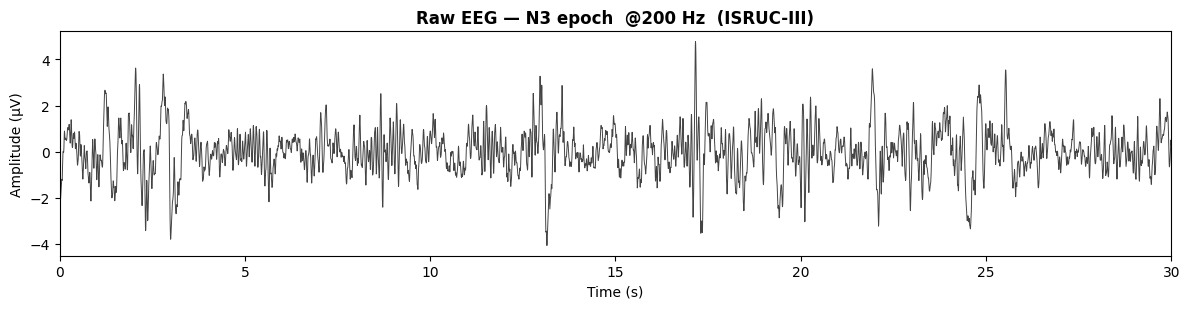

In [7]:
# ── Load local ISRUC-III data (.rec + annotation .txt) ────────────────────
import os, shutil, mne, numpy as np, matplotlib.pyplot as plt
from sleep_quality_model import EEGPreprocessor, SleepDataLoader

DATA_DIR = CONFIG["data_dir"]
CH       = CONFIG["eeg_channel"]
N        = CONFIG["n_subjects"]
SR       = CONFIG["sampling_rate"]   # 200 Hz

# ISRUC-III stage mapping: raw label -> internal (0=W,1=N1,2=N2,3=N3,4=REM)
STAGE_MAP_ISRUC = {
    0: 0,   # Wake
    1: 1,   # N1
    2: 2,   # N2
    3: 3,   # N3 (SWS)
    4: 3,   # N4 -> N3 (old AASM)
    5: 4,   # REM
    6: -1,  # Movement / artifact -> discard
    9: -1,  # Unknown -> discard
}

def find_rec_files_isruc(data_dir, n_subjects):
    """Find .rec files using os.listdir to avoid glob spaces-in-path bug.
    Supports both flat layout (data_dir/N.rec) and
    subfolder layout (data_dir/N/N.rec)."""
    rec_files = []
    for subj_id in range(1, n_subjects + 1):
        # Try subfolder layout first: data_dir/1/1.rec
        subj_folder = os.path.join(data_dir, str(subj_id))
        found = False
        if os.path.isdir(subj_folder):
            for fname in os.listdir(subj_folder):
                if fname.lower().endswith(".rec"):
                    rec_files.append(os.path.join(subj_folder, fname))
                    found = True
                    break
        if not found:
            # Try flat layout: data_dir/1.rec or data_dir/SN001.rec
            for fname in os.listdir(data_dir):
                if fname.lower().endswith(".rec") and (
                    fname.startswith(str(subj_id)) or
                    fname.upper().startswith(f"SN{subj_id:03d}")
                ):
                    rec_files.append(os.path.join(data_dir, fname))
                    break
    return sorted(rec_files)

def parse_isruc_txt(txt_path):
    """Read ISRUC-III text annotation (one integer per line)."""
    stages = []
    with open(txt_path, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or not line[0].isdigit():
                continue
            try:
                raw_stage = int(line.split()[0])
                stages.append(STAGE_MAP_ISRUC.get(raw_stage, -1))
            except ValueError:
                continue
    return np.array(stages, dtype=np.int64)

def load_isruc_annotations(name, subj_dir):
    """Load annotation from subj_dir. Try _1.txt first."""
    txt = os.path.join(subj_dir, f"{name}_1.txt")
    if os.path.exists(txt):
        labels = parse_isruc_txt(txt)
        if len(labels) > 0:
            return labels, 'txt'
    return None, None

# ── Main loading loop ──────────────────────────────────────────────────────
rec_paths = find_rec_files_isruc(DATA_DIR, N)
pre = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
all_eeg, all_delta, all_stage, all_quality = [], [], [], []
night_ids = []

print(f"Found {len(rec_paths)} .rec files. Loading...\n")
for rec_path in rec_paths:
    name     = os.path.splitext(os.path.basename(rec_path))[0]   # "1", "2", ...
    subj_dir = os.path.dirname(rec_path)
    sid      = int(name.replace("SN", "").lstrip("0") or "0")
    print(f"  [Subject {sid}] ", end="", flush=True)

    labels, ann_src = load_isruc_annotations(name, subj_dir)
    if labels is None:
        print("✗ no annotation"); continue

    try:
        # Copy .rec -> /tmp/*.edf to bypass MNE extension check
        tmp_path = f"/tmp/_isruc_{name}.edf"
        if not os.path.exists(tmp_path):
            shutil.copy2(rec_path, tmp_path)

        raw = mne.io.read_raw_edf(tmp_path, preload=True, verbose=False)
        if raw.info['sfreq'] != SR:
            raw.resample(SR, verbose=False)

        # Channel selection
        ch = None
        for candidate in [CH, 'C4-A1', 'F4-A1', 'C3-A2']:
            if candidate in raw.ch_names:
                ch = candidate; break
        if ch is None:
            ch = raw.ch_names[0]
        eeg = raw.get_data(picks=[ch], units='uV')[0].astype(np.float32)

        epochs, deltas, lbls = pre.create_epochs(eeg, labels=labels)

        # Align label count with epoch count
        if len(lbls) > len(epochs):
            lbls = lbls[:len(epochs)]
        elif len(lbls) < len(epochs):
            pad = np.full(len(epochs) - len(lbls), -1, dtype=np.int64)
            lbls = np.concatenate([lbls, pad])

        valid = lbls != -1
        epochs, deltas, lbls = epochs[valid], deltas[valid], lbls[valid]
        if len(epochs) == 0:
            print("no valid epochs"); continue

        quality = SleepDataLoader._delta_to_quality(deltas)
        all_eeg.append(epochs)
        all_delta.append(deltas)
        all_stage.append(lbls)
        all_quality.append(quality)
        night_ids.extend([sid] * len(epochs))
        print(f"✓ {len(epochs)} epochs  (ch={ch}, ann={ann_src})")

    except Exception as e:
        print(f"✗ {e}")

if not all_eeg:
    raise RuntimeError("No data loaded! Check DATA_DIR: " + DATA_DIR)

raw_eegs       = np.concatenate(all_eeg).astype(np.float32)
delta_powers   = np.concatenate(all_delta).reshape(-1, 1).astype(np.float32)
stage_labels   = np.concatenate(all_stage).astype(np.int64)
quality_labels = np.concatenate(all_quality).astype(np.float32)
night_ids      = np.array(night_ids)

print(f"\n── Dataset loaded ───────────────────────────────────────")
print(f"  Total epochs : {raw_eegs.shape[0]:,}")
print(f"  Signal shape : {raw_eegs.shape}")
print(f"  Subjects     : {len(np.unique(night_ids))}")
print(f"  Stage distribution:")
unique, counts = np.unique(stage_labels, return_counts=True)
for u, c in zip(unique, counts):
    pct = c / len(stage_labels) * 100
    print(f"    {STAGE_MAP[u]:>5}: {c:5d} ({pct:.1f}%)")

# Plot a sample N3 epoch
ex_idx = np.where(stage_labels == 3)[0][0] if (stage_labels == 3).any() else 0
example = raw_eegs[ex_idx]
t = np.arange(len(example)) / SR
fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, example, color='#444', lw=0.7)
ax.set_title(f'Raw EEG — {STAGE_MAP[stage_labels[ex_idx]]} epoch  @{SR} Hz  (ISRUC-III)', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Amplitude (μV)'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()


In [8]:
# ── Option A: rebuild quality labels as N3-only ──────────────────────────────
# Replace global min-max quality with N3-specific normalization.
# Non-N3 epochs get quality=0.0 and are masked from L_qual during training.
quality_labels = make_n3_quality_labels(delta_powers.flatten(), stage_labels)

n3_count = int((stage_labels == 3).sum())
total    = len(stage_labels)
print(f'Quality labels rebuilt (N3-only):')
print(f'  N3 epochs with quality scores : {n3_count}')
print(f'  Non-N3 epochs (quality=0.0)   : {total - n3_count}')
if n3_count > 0:
    n3_q = quality_labels[stage_labels==3]
    print(f'  N3 quality range : {n3_q.min():.3f} -- {n3_q.max():.3f}  mean={n3_q.mean():.3f}')


Quality labels rebuilt (N3-only):
  N3 epochs with quality scores : 2035
  Non-N3 epochs (quality=0.0)   : 6854
  N3 quality range : 0.000 -- 1.000  mean=0.670


## 3. Step 2 — Preprocessing, one transformation at a time

The preprocessing block has three sub-steps. We show the **before vs after** of each so you can see
exactly what it does.

### 3.1 Band-pass filter (0.5-40 Hz)

**What is happening:** A 4th-order Butterworth band-pass keeps only frequencies between 0.5 and 40 Hz.

**Why:** Below 0.5 Hz is mostly slow electrode drift / sweat artifacts; above ~40 Hz is muscle
activity and electrical noise - neither helps sleep staging, so we drop both.

**What to look for:** the bottom (filtered) trace is cleaner and more centered than the top (raw)
trace, but the overall wave shape is preserved.

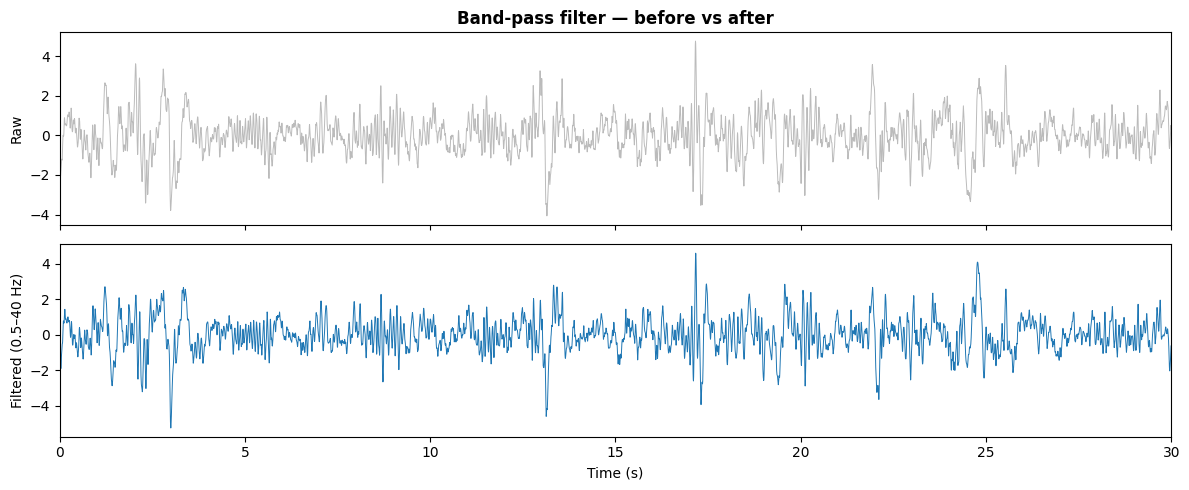

raw std=1.00  ->  filtered std=0.99


In [9]:
filtered = pre.bandpass_filter(example)

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, example, color='#bbb', lw=0.7); axes[0].set_ylabel('Raw'); axes[0].set_title('Band-pass filter — before vs after', fontweight='bold')
axes[1].plot(t, filtered, color='#1f77b4', lw=0.7); axes[1].set_ylabel('Filtered (0.5–40 Hz)')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
plt.tight_layout(); plt.show()
print(f"raw std={example.std():.2f}  ->  filtered std={filtered.std():.2f}")

### 3.2 Normalize (z-score)

**What is happening:** Rescale the epoch to **mean 0, std 1** (`(x - mean) / std`).

**Why:** absolute EEG amplitude varies by person, electrode, and night. Z-scoring makes every epoch
comparable so the network learns physiology, not the recording setup.

**What to look for:** identical wave shape, but the y-axis is now in standard-deviation units; printed
mean ~ 0 and std ~ 1.

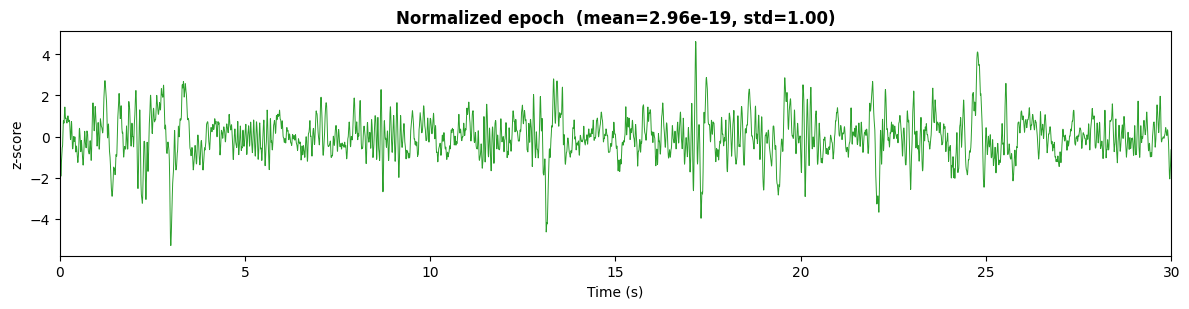

In [10]:
norm = pre.normalize_epoch(filtered)

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.plot(t, norm, color='#2ca02c', lw=0.7)
ax.set_title(f'Normalized epoch  (mean={norm.mean():.2e}, std={norm.std():.2f})', fontweight='bold')
ax.set_xlabel('Time (s)'); ax.set_ylabel('z-score'); ax.set_xlim(0, 30)
plt.tight_layout(); plt.show()

### 3.3 Extract delta power (0.5-4 Hz)

**What is happening:** isolate the **delta band (0.5-4 Hz)** and compute its **power** = mean of the
squared signal (one number per epoch).

**Why:** delta is the signature of deep N3 sleep. High delta power -> more deep sleep -> higher quality.
This number becomes the **handcrafted feature** fused into the network, injecting domain knowledge.

**What to look for:** the red "delta only" trace is a smooth slow wave (fast wiggles gone); the boxed
delta-power value is high for this N3 epoch. The printout shows all five band powers - delta should lead.

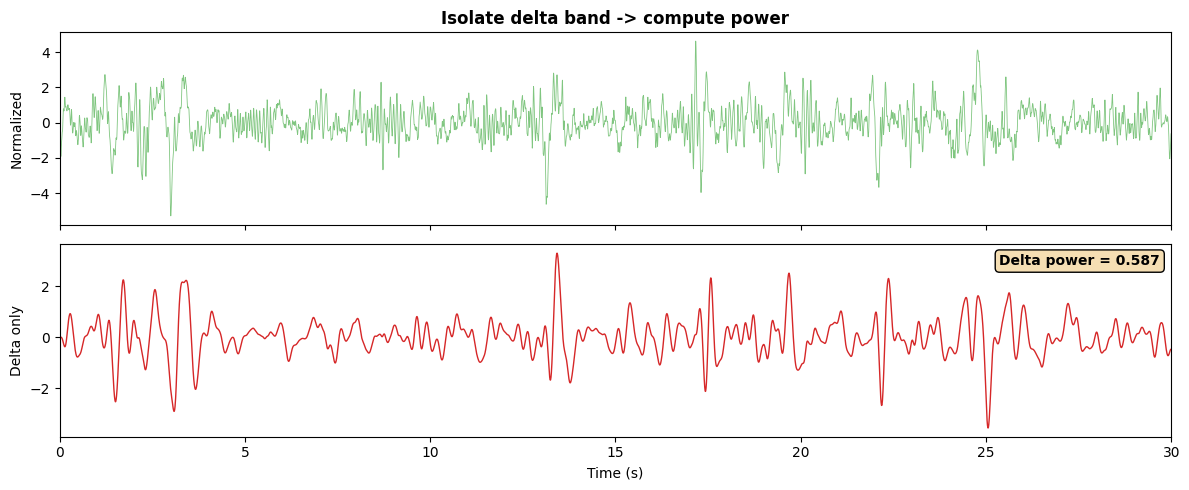

Band powers: {'delta': 0.587, 'theta': 0.162, 'alpha': 0.164, 'sigma': 0.061, 'beta': 0.026}


In [ ]:
sos_delta = butter(4, [0.5, 4], btype='band', fs=SR, output='sos')
delta_sig = sosfilt(sos_delta, norm)
power = float(np.mean(delta_sig ** 2))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, norm, color='#2ca02c', lw=0.6, alpha=0.6); axes[0].set_ylabel('Normalized'); axes[0].set_title('Isolate delta band -> compute power', fontweight='bold')
axes[1].plot(t, delta_sig, color='#d62728', lw=1); axes[1].set_ylabel('Delta only')
axes[1].set_xlabel('Time (s)'); axes[1].set_xlim(0, 30)
axes[1].text(0.99, 0.95, f'Delta power = {power:.3f}', transform=axes[1].transAxes,
             ha='right', va='top', fontweight='bold', bbox=dict(boxstyle='round', facecolor='wheat'))
plt.tight_layout(); plt.show()

# all five bands for this epoch
bands = pre.extract_frequency_bands(norm)
print("Band powers:", {k: round(v, 3) for k, v in bands.items()})

## 4. Step 3 — Epoching & the full dataset

The steps above happen for **every** 30-s epoch. The dataset now holds all epochs with their delta
power, stage label, and a quality label derived from normalized delta power (per night). When you
pool several nights (`data_source` = `"download"` or `"folder"`), `night_ids` records which recording
each epoch came from — used later for the per-night timeline.

The data source is set once in `CONFIG` (§1); nothing here needs editing to switch datasets.

raw_eegs      : (8889, 6000)
delta_powers  : (8889, 1)
stage_labels  : (8889,)
quality_labels: (8889, 1)
nights pooled : 10


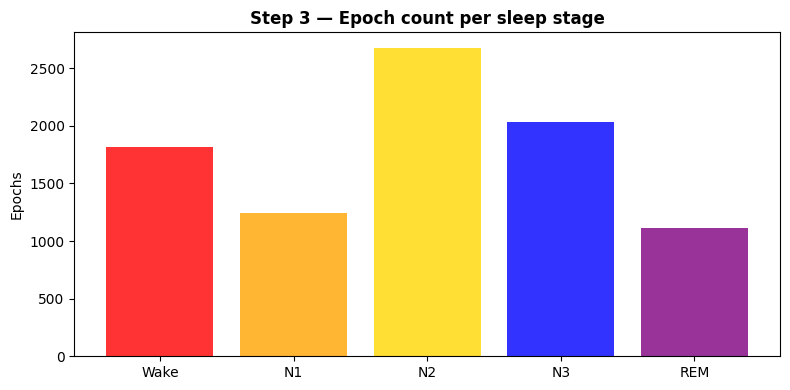

In [ ]:
# এই line গুলো আগে থেকেই থাকার কথা ছিল — এখন define করো
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

print("raw_eegs      :", raw_eegs.shape)
print("delta_powers  :", delta_powers.shape)
print("stage_labels  :", stage_labels.shape)
print("quality_labels:", quality_labels.shape)
if night_ids is not None:
    print("nights pooled :", len(np.unique(night_ids)))

stages, counts = np.unique(stage_labels, return_counts=True)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([STAGE_MAP[s] for s in stages], counts,
       color=[STAGE_COLORS[s] for s in stages], alpha=0.8)
ax.set_title('Step 3 — Epoch count per sleep stage', fontweight='bold')
ax.set_ylabel('Epochs')
plt.tight_layout()
plt.show()

## 5. Step 4 — Validate the features across all epochs

Before training, sanity-check that the features behave physiologically. The single most important
check: **N3 (deep sleep) should have the highest delta power.** If that holds, the signal pipeline is trustworthy.

| What to look for | ❌ If wrong |
|---|---|
| Boxplot: N3 > others; PSD: delta peak highest | N3 not highest → labels wrong or feature extraction wrong |

In [12]:
STAGE_MAP    = {0:'Wake', 1:'N1', 2:'N2', 3:'N3', 4:'REM'}
STAGE_COLORS = ['red', 'orange', 'gold', 'blue', 'purple']

/var/folders/fs/csz467_d6lzd3c40xv8w1tg40000gn/T/ipykernel_14389/1814202931.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[0].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)


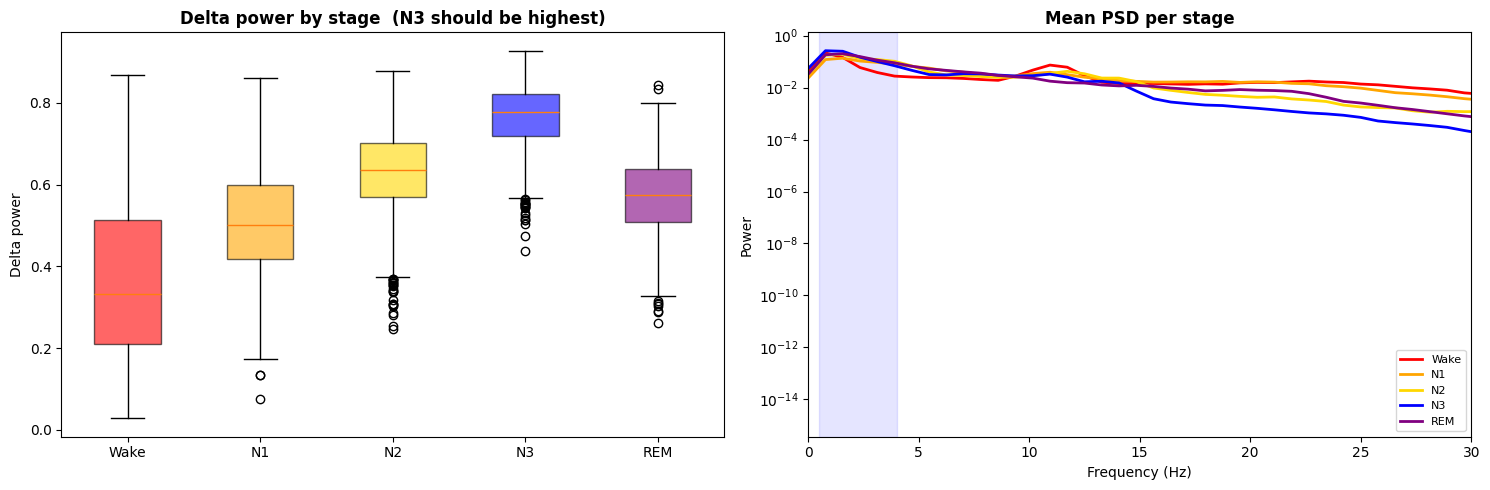

Median delta power per stage: {'Wake': 0.333, 'N1': 0.501, 'N2': 0.635, 'N3': 0.777, 'REM': 0.575}


In [13]:
from scipy.signal import welch
dp = delta_powers.flatten()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# delta power per stage (boxplot)
data = [dp[stage_labels == s] for s in range(5)]
bp = axes[0].boxplot(data, labels=[STAGE_MAP[s] for s in range(5)], patch_artist=True)
for patch, c in zip(bp['boxes'], STAGE_COLORS):
    patch.set_facecolor(c); patch.set_alpha(0.6)
axes[0].set_title('Delta power by stage  (N3 should be highest)', fontweight='bold')
axes[0].set_ylabel('Delta power')

# mean PSD per stage
for s in range(5):
    idx = np.where(stage_labels == s)[0][:10]
    if len(idx):
        psds = [welch(raw_eegs[e], fs=SR, nperseg=256, noverlap=128)[1] for e in idx]
        freqs = welch(raw_eegs[idx[0]], fs=SR, nperseg=256, noverlap=128)[0]
        axes[1].semilogy(freqs, np.mean(psds, axis=0), color=STAGE_COLORS[s], lw=2, label=STAGE_MAP[s])
axes[1].axvspan(0.5, 4, alpha=0.1, color='blue')
axes[1].set_xlim(0, 30); axes[1].set_title('Mean PSD per stage', fontweight='bold')
axes[1].set_xlabel('Frequency (Hz)'); axes[1].set_ylabel('Power'); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Median delta power per stage:",
      {STAGE_MAP[s]: round(float(np.median(dp[stage_labels==s])), 3) for s in range(5)})

### 5b. Delta power across the night (timeline)

**What is happening:** delta power for **every epoch in chronological order**, sleep onset (left) to
morning (right), colored by stage. When several nights are pooled, each night is normalized to its own
0-1 time axis and overlaid so they line up.

**Why:** healthy sleep front-loads deep sleep - most N3 (highest delta) is in the **first half** of the
night, tapering as REM rises. A strong end-to-end check that signal processing *and* epoch ordering are correct.

| What to look for | If wrong |
|---|---|
| High delta early, lower delta late | Flat / reversed -> suspicious data or shuffled epochs |

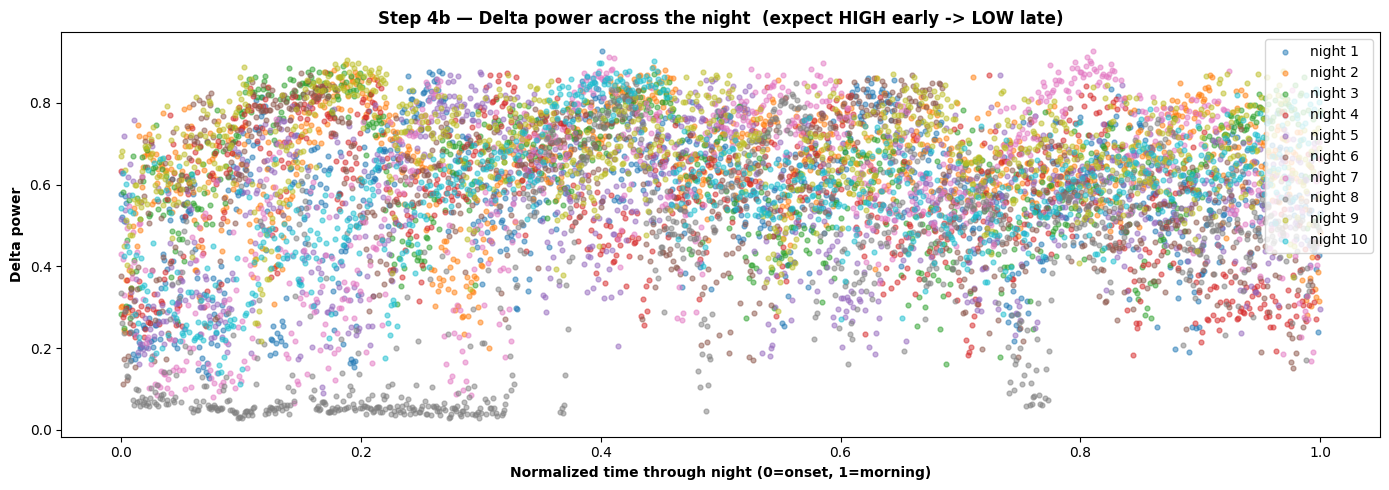

Mean delta power - first half: 0.572  |  second half: 0.592
Note: early <= late - expected for pooled/real data with little deep sleep.


In [14]:
fig, ax = plt.subplots(figsize=(14, 5))

if night_ids is not None and len(np.unique(night_ids)) > 1:
    # pooled: overlay each night on a normalized 0-1 time axis
    for nid in np.unique(night_ids):
        m = night_ids == nid
        d = delta_powers.flatten()[m]
        x = np.linspace(0, 1, len(d))
        ax.scatter(x, d, s=12, alpha=0.5, label=f'night {nid}')
    ax.set_xlabel('Normalized time through night (0=onset, 1=morning)', fontweight='bold')
    # average trend across nights
    ax.legend(fontsize=8, ncol=min(6, len(np.unique(night_ids))))
    first_vals, second_vals = [], []
    for nid in np.unique(night_ids):
        d = delta_powers.flatten()[night_ids == nid]
        h = len(d)//2
        first_vals.append(d[:h].mean()); second_vals.append(d[h:].mean())
    fh, sh = np.mean(first_vals), np.mean(second_vals)
else:
    dp = delta_powers.flatten()
    epochs = np.arange(len(dp)); mid = len(dp)//2
    sc = ax.scatter(epochs, dp, c=stage_labels, cmap='RdYlBu_r', s=35, alpha=0.8)
    ax.axvline(mid, color='black', ls='--', lw=2, alpha=0.6, label='night midpoint')
    ax.axvspan(0, mid, color='green', alpha=0.07)
    ax.axvspan(mid, len(dp), color='red', alpha=0.07)
    z = np.polyfit(epochs, dp, 1)
    ax.plot(epochs, np.poly1d(z)(epochs), 'k-', lw=2, alpha=0.7, label='trend')
    cb = plt.colorbar(sc, ax=ax); cb.set_label('Stage (0=W .. 4=REM)', fontweight='bold')
    ax.set_xlabel('Epoch (chronological, 30-s each)', fontweight='bold')
    fh, sh = dp[:mid].mean(), dp[mid:].mean()

ax.set_ylabel('Delta power', fontweight='bold')
ax.set_title('Step 4b — Delta power across the night  (expect HIGH early -> LOW late)', fontweight='bold')
ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

print(f"Mean delta power - first half: {fh:.3f}  |  second half: {sh:.3f}")
print("Pattern OK (early > late)." if fh > sh else
      "Note: early <= late - expected for pooled/real data with little deep sleep.")

## 6. Step 5 -- Build the binary N3 model

**Architecture (Option A):**
1. 1D-CNN -- local temporal features
2. BiLSTM -- sequential context
3. Attention -- weights informative segments
4. Delta fusion (RQ2) -- explicit physiological feature
5. Two heads: `n3_head` (binary logit) + `quality_head` (N3 quality [0,1])

| Output | Shape | Meaning |
|---|---|---|
| `n3_logit` | (B,1) | Raw logit -> sigmoid -> P(N3) |
| `quality`  | (B,1) | N3 sleep quality 0-1 (x100 = score) |


In [15]:
model = SleepQualityNet(input_length=SR*30, use_delta=True)
n_params = sum(p.numel() for p in model.parameters())
print(f'SleepQualityNet (binary N3) -- {n_params:,} parameters')
print('Heads: n3_head (binary BCE logit) | quality_head ([0,1] x100)')

xb = torch.FloatTensor(raw_eegs[:4]).unsqueeze(1)
db = torch.FloatTensor(delta_powers[:4])
with torch.no_grad():
    n3_logit, quality = model(xb, db)
print('n3_logit :', tuple(n3_logit.shape), '-> sigmoid -> P(N3)')
print('quality  :', tuple(quality.shape),  '-> x100 = quality score')
print('N3 probs (batch):', [f'{p:.3f}' for p in torch.sigmoid(n3_logit).squeeze().tolist()])


SleepQualityNet (binary N3) -- 921,187 parameters
Heads: n3_head (binary BCE logit) | quality_head ([0,1] x100)
n3_logit : (4, 1) -> sigmoid -> P(N3)
quality  : (4, 1) -> x100 = quality score
N3 probs (batch): ['0.516', '0.375', '0.431', '0.455']


## 7. Step 6 -- Train, watch N3 Recall and AUC rise

Loss: `L_total = lam_cls*L_cls + lam_qual*L_qual(N3 only) + lam_phys*L_phys(N3 only)`

| Contribution | Code | RQ |
|---|---|---|
| Binary N3 detection + quality | `n3_head` (BCE) + `quality_head` (SmoothL1 N3-only) | RQ1 |
| Delta-power fusion | `cat([attended, delta])` in `fusion` | RQ2 |
| N3 pos_weight upweighting | `BCEWithLogitsLoss(pos_weight=2.0)` | RQ3 |

**Key metrics to watch:** N3 Recall up, N3 F1 up, AUC up, Quality RMSE down


N3 pos_weight = 2.0 -- penalises missed N3 2.0x more than false alarms
  loss=0.2041/0.4734  N3-Recall=0.997  N3-F1=0.642  AUC=0.982  Q-RMSE=0.086
  loss=0.0967/0.3250  N3-Recall=0.995  N3-F1=0.712  AUC=0.984  Q-RMSE=0.084
  loss=0.0699/0.1260  N3-Recall=0.878  N3-F1=0.867  AUC=0.986  Q-RMSE=0.107
  loss=0.0613/0.2513  N3-Recall=0.997  N3-F1=0.742  AUC=0.988  Q-RMSE=0.060
  loss=0.0424/0.5768  N3-Recall=0.997  N3-F1=0.595  AUC=0.986  Q-RMSE=0.065
  loss=0.0388/0.1876  N3-Recall=0.989  N3-F1=0.793  AUC=0.989  Q-RMSE=0.053
  loss=0.0299/0.1539  N3-Recall=0.973  N3-F1=0.823  AUC=0.987  Q-RMSE=0.053
  loss=0.0277/0.1677  N3-Recall=0.986  N3-F1=0.800  AUC=0.988  Q-RMSE=0.051
  loss=0.0073/0.1899  N3-Recall=0.981  N3-F1=0.794  AUC=0.986  Q-RMSE=0.076
  loss=-0.0002/0.5646  N3-Recall=0.997  N3-F1=0.639  AUC=0.987  Q-RMSE=0.049


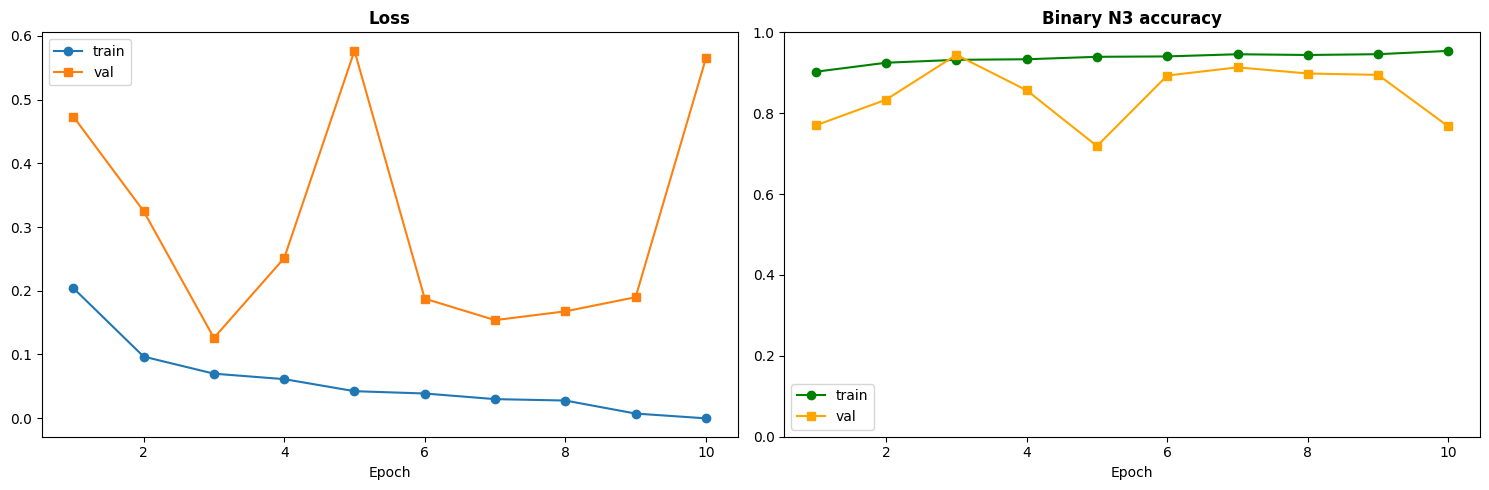

In [16]:
split     = int(0.8 * len(raw_eegs))
train_ds  = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[:split], delta_powers[:split], stage_labels[:split], quality_labels[:split])
val_ds    = SleepDataLoader.numpy_to_tensor_dataset(
    raw_eegs[split:], delta_powers[split:], stage_labels[split:], quality_labels[split:])
train_loader = torch.utils.data.DataLoader(
    train_ds, batch_size=CONFIG['batch_size'], shuffle=True, drop_last=True)
val_loader   = torch.utils.data.DataLoader(
    val_ds,   batch_size=CONFIG['batch_size'], shuffle=False)

model   = SleepQualityNet(input_length=SR*30, use_delta=True)
trainer = SleepQualityTrainer(model, checkpoint_path='best_model.pth',
                              n3_pos_weight=CONFIG['n3_loss_weight'])
print(f'N3 pos_weight = {CONFIG["n3_loss_weight"]}'
      f' -- penalises missed N3 {CONFIG["n3_loss_weight"]}x more than false alarms')
trainer.train(train_loader, val_loader, epochs=CONFIG['epochs'], verbose=False)

ep = np.arange(1, len(trainer.train_losses)+1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(ep, trainer.train_losses, 'o-', label='train')
axes[0].plot(ep, trainer.val_losses,   's-', label='val')
axes[0].set_title('Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].legend()
axes[1].plot(ep, trainer.train_accs, 'o-', color='green', label='train')
axes[1].plot(ep, trainer.val_accs,   's-', color='orange', label='val')
axes[1].set_title('Binary N3 accuracy', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylim(0,1); axes[1].legend()
plt.tight_layout(); plt.show()


## 8. Step 7 -- Evaluate: binary N3 metrics + N3 quality scatter

| Metric | Meaning | Target |
|---|---|---|
| N3 Recall | Caught real N3 epochs / all real N3 (RQ1/RQ3) | > 0.70 |
| N3 Precision | Correct N3 predictions / all N3 predictions | > 0.70 |
| N3 F1 | Harmonic mean (ablation anchor) | > 0.70 |
| ROC-AUC | Overall N3 discrimination (RQ2) | > 0.85 |
| Quality R2 | Quality score tracks ground truth | > 0.50 |


  N3 Recall    : 0.9973   (RQ1 + RQ3 primary)
  N3 Precision : 0.4705
  N3 F1        : 0.6394   (ablation anchor)
  ROC-AUC      : 0.9871   (RQ2 fusion benefit)
  Quality RMSE : 4.92  (N3 epochs only)
  Quality R2   : 0.8757


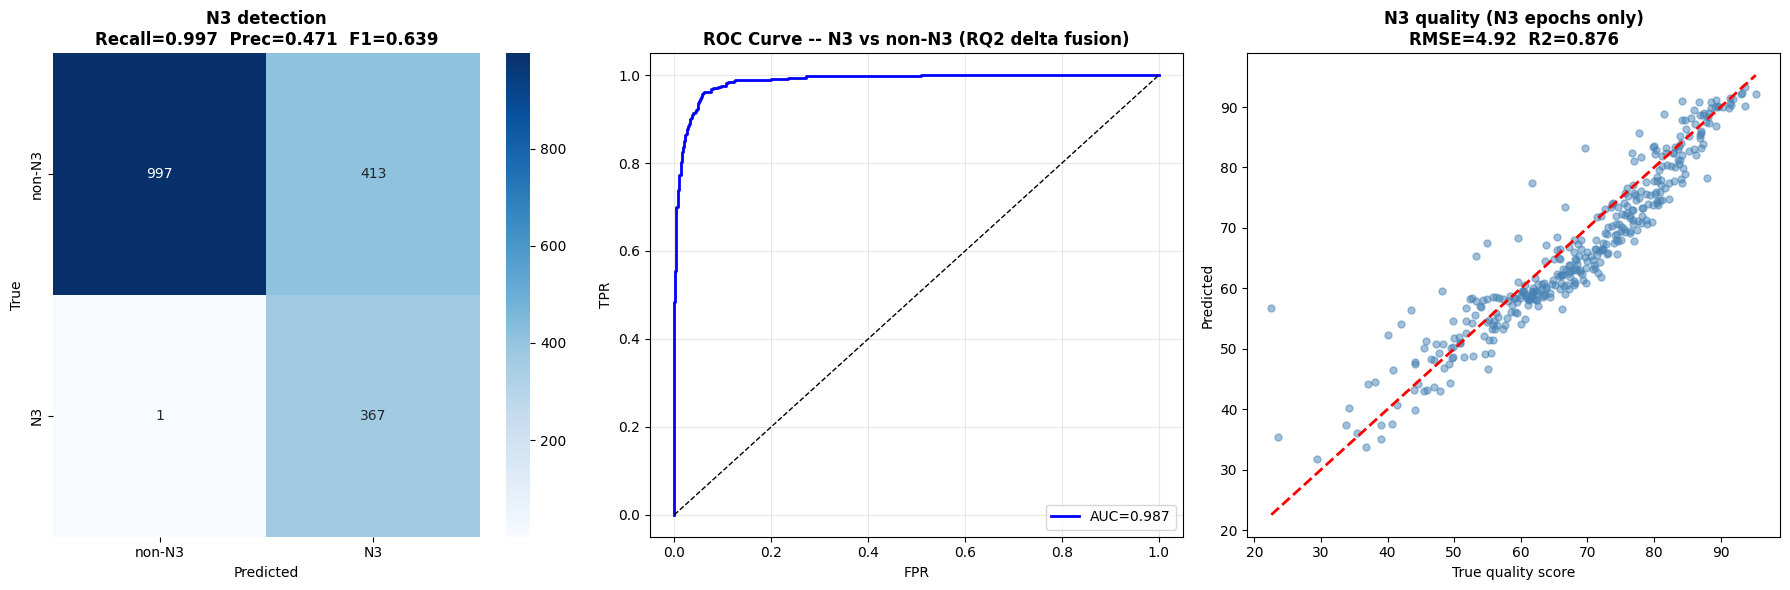

In [17]:
import seaborn as sns
from sklearn.metrics import (confusion_matrix, roc_curve, auc,
                             recall_score, precision_score, f1_score, roc_auc_score)

model.eval()
yt_n3, yp_n3, yp_prob = [], [], []
yt_q,  yp_q           = [], []
with torch.no_grad():
    for raw_eeg, delta, s_lab, q_lab in val_loader:
        n3_logit, q_pred = model(raw_eeg, delta)
        prob    = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred    = (prob > 0.5).astype(int)
        true_n3 = (s_lab.numpy() == 3).astype(int)
        yp_prob.extend(prob); yp_n3.extend(pred); yt_n3.extend(true_n3)
        mask = (true_n3 == 1)
        if mask.any():
            yt_q.extend(q_lab.numpy().flatten()[mask]*100)
            yp_q.extend(q_pred.cpu().numpy().flatten()[mask]*100)

yt_n3 = np.array(yt_n3); yp_n3 = np.array(yp_n3)
yp_prob = np.array(yp_prob)
yt_q = np.array(yt_q); yp_q = np.array(yp_q)

rec     = recall_score(yt_n3, yp_n3, zero_division=0)
prec    = precision_score(yt_n3, yp_n3, zero_division=0)
f1      = f1_score(yt_n3, yp_n3, zero_division=0)
auc_val = roc_auc_score(yt_n3, yp_prob) if len(np.unique(yt_n3))>1 else 0
rmse_q  = float(np.sqrt(np.mean((yt_q-yp_q)**2))) if len(yt_q)>0 else 0
denom   = np.sum((yt_q-yt_q.mean())**2) if len(yt_q)>0 else 1
r2_q    = float(1-np.sum((yt_q-yp_q)**2)/denom) if len(yt_q)>0 else 0

print('='*55)
print(f'  N3 Recall    : {rec:.4f}   (RQ1 + RQ3 primary)')
print(f'  N3 Precision : {prec:.4f}')
print(f'  N3 F1        : {f1:.4f}   (ablation anchor)')
print(f'  ROC-AUC      : {auc_val:.4f}   (RQ2 fusion benefit)')
print(f'  Quality RMSE : {rmse_q:.2f}  (N3 epochs only)')
print(f'  Quality R2   : {r2_q:.4f}')
print('='*55)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Panel 1: binary confusion matrix
cm = confusion_matrix(yt_n3, yp_n3)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['non-N3','N3'], yticklabels=['non-N3','N3'])
axes[0].set_title(f'N3 detection\nRecall={rec:.3f}  Prec={prec:.3f}  F1={f1:.3f}',
                  fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('True')

# Panel 2: ROC curve
fpr, tpr, _ = roc_curve(yt_n3, yp_prob)
axes[1].plot(fpr, tpr, 'b-', lw=2, label=f'AUC={auc_val:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1)
axes[1].set_xlabel('FPR'); axes[1].set_ylabel('TPR')
axes[1].set_title('ROC Curve -- N3 vs non-N3 (RQ2 delta fusion)', fontweight='bold')
axes[1].legend(); axes[1].grid(alpha=0.3)

# Panel 3: quality scatter (N3 only)
if len(yt_q)>0:
    axes[2].scatter(yt_q, yp_q, alpha=0.5, s=25, color='steelblue')
    lo,hi = min(yt_q.min(),yp_q.min()), max(yt_q.max(),yp_q.max())
    axes[2].plot([lo,hi],[lo,hi],'r--',lw=2)
    axes[2].set_title(f'N3 quality (N3 epochs only)\nRMSE={rmse_q:.2f}  R2={r2_q:.3f}',
                     fontweight='bold')
    axes[2].set_xlabel('True quality score'); axes[2].set_ylabel('Predicted')
else:
    axes[2].text(0.5,0.5,'No N3 in val set',ha='center',va='center',
                transform=axes[2].transAxes)

plt.tight_layout()
plt.savefig('/tmp/eval_binary_n3.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Step 8 — Explainability: which band drives each stage?

Mean band power per stage, computed from the data. Delta should dominate for N3 — confirming the
model's most informative feature is physiologically sensible.

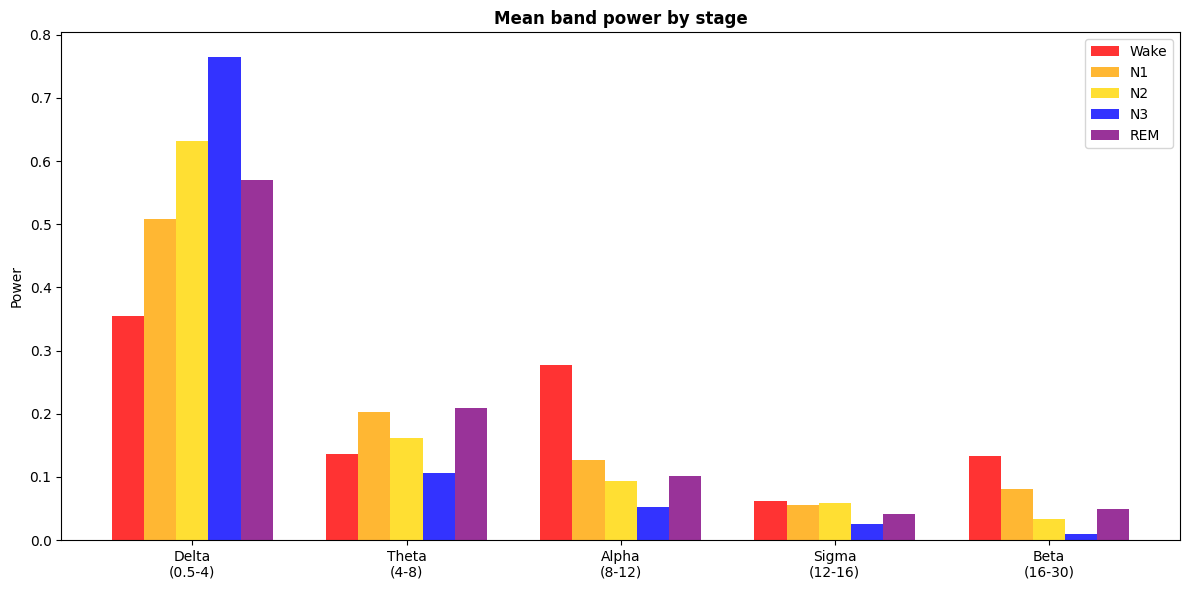

In [18]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_names = ['Delta\n(0.5-4)','Theta\n(4-8)','Alpha\n(8-12)','Sigma\n(12-16)','Beta\n(16-30)']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(band_names)); w = 0.15
for s in range(5):
    mask = stage_labels == s
    if mask.sum():
        ax.bar(x + w*s, powers[mask].mean(axis=0), w, label=STAGE_MAP[s], color=STAGE_COLORS[s], alpha=0.8)
ax.set_xticks(x + w*2); ax.set_xticklabels(band_names)
ax.set_title('Mean band power by stage', fontweight='bold'); ax.set_ylabel('Power'); ax.legend()
plt.tight_layout(); plt.show()

### 9b. Feature importance — which band matters most?

**What is happening:** summarize how strongly each frequency band separates the sleep stages into a
single **importance score per band** (between-stage variance of mean power, normalized to sum to 1), then rank.

**Why:** the headline interpretability check. The model fuses delta power explicitly because delta
should be most discriminative for deep sleep - this confirms that holds in your data.

| What to look for | If wrong |
|---|---|
| Delta ranked highest | Beta/alpha highest -> wrong features or noisy signal |

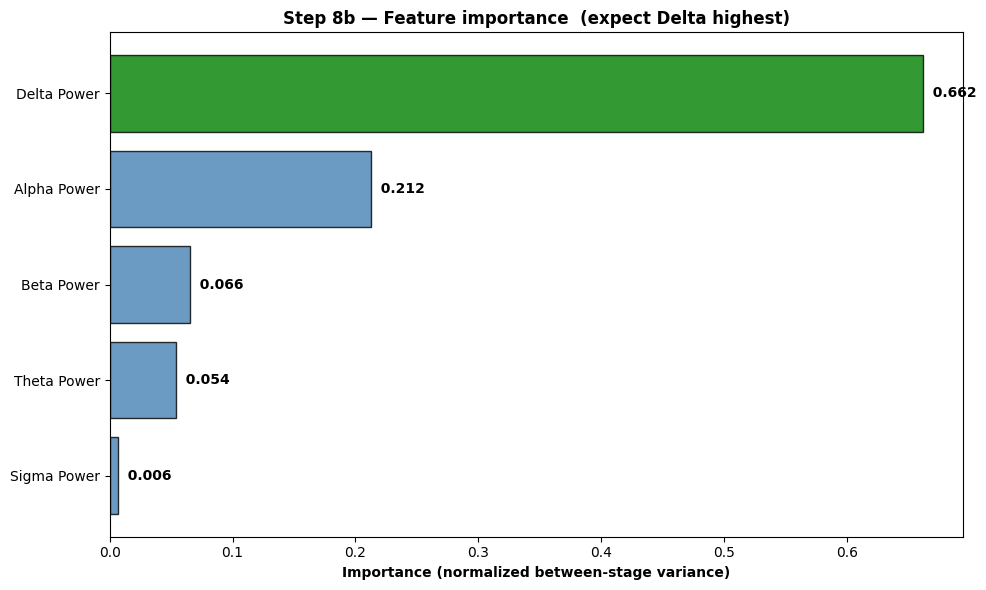

Ranking: {'Delta Power': 0.662, 'Alpha Power': 0.212, 'Beta Power': 0.066, 'Theta Power': 0.054, 'Sigma Power': 0.006}


In [19]:
band_keys = ['delta','theta','alpha','sigma','beta']
band_disp = ['Delta Power','Theta Power','Alpha Power','Sigma Power','Beta Power']
powers = np.array([[pre.extract_frequency_bands(e)[k] for k in band_keys] for e in raw_eegs])

stage_means = np.array([powers[stage_labels == s].mean(axis=0)
                        for s in range(5) if (stage_labels == s).any()])
importance = stage_means.var(axis=0); importance = importance / importance.sum()

order = np.argsort(importance)[::-1]
names = [band_disp[i] for i in order]; scores = importance[order]
colors = ['green' if n == 'Delta Power' else 'steelblue' for n in names]

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(names, scores, color=colors, alpha=0.8, edgecolor='black'); ax.invert_yaxis()
for i, sc in enumerate(scores):
    ax.text(sc, i, f'  {sc:.3f}', va='center', fontweight='bold')
ax.set_xlabel('Importance (normalized between-stage variance)', fontweight='bold')
ax.set_title('Step 8b — Feature importance  (expect Delta highest)', fontweight='bold')
plt.tight_layout(); plt.show()
print("Ranking:", {n: round(float(s), 3) for n, s in zip(names, scores)})

## 10. Step 9 — Inference on a single epoch

**What is happening:** the end-to-end payoff - load the best checkpoint, feed **one** epoch, read off
the predicted stage + quality score.

**Why:** this is exactly how the model is used on a new recording: one epoch in, a stage label +
0-100 quality score out.

**What to look for:** predicted stage (with confidence %) and quality score, printed beside the **true**
stage so you can see whether it matched.

In [20]:
infer = SleepQualityNet(input_length=SR*30, use_delta=True)
infer.load_state_dict(torch.load('best_model.pth'))
infer.eval()

i  = split
xe = torch.FloatTensor(raw_eegs[i:i+1]).unsqueeze(1)
de = torch.FloatTensor(delta_powers[i:i+1])
with torch.no_grad():
    n3_logit, quality = infer(xe, de)

prob    = float(torch.sigmoid(n3_logit).item())
is_n3   = prob > 0.5
true_n3 = int(stage_labels[i]) == 3
print('=== Single-epoch inference ===')
print(f'  P(N3)          : {prob:.4f}  ({"N3" if is_n3 else "non-N3"})')
print(f'  True stage     : {STAGE_MAP[int(stage_labels[i])]}')
print(f'  Correct        : {is_n3 == true_n3}')
if is_n3:
    print(f'  Quality score  : {quality.item()*100:.1f} / 100')
else:
    print('  Quality score  : N/A (epoch predicted non-N3)')


=== Single-epoch inference ===
  P(N3)          : 0.0011  (non-N3)
  True stage     : Wake
  Correct        : True
  Quality score  : N/A (epoch predicted non-N3)


## 11. XAI — Attention Weight Visualization (RQ2)

**What is happening:** The BiLSTM attention layer assigns a weight to each CNN feature.
Here we extract those weights and visualize them alongside the raw EEG signal.

**What to look for:**
- High attention on delta-rich segments → confirms model focuses on physiologically relevant features
- N3 epochs should show highest attention on slow-wave portions

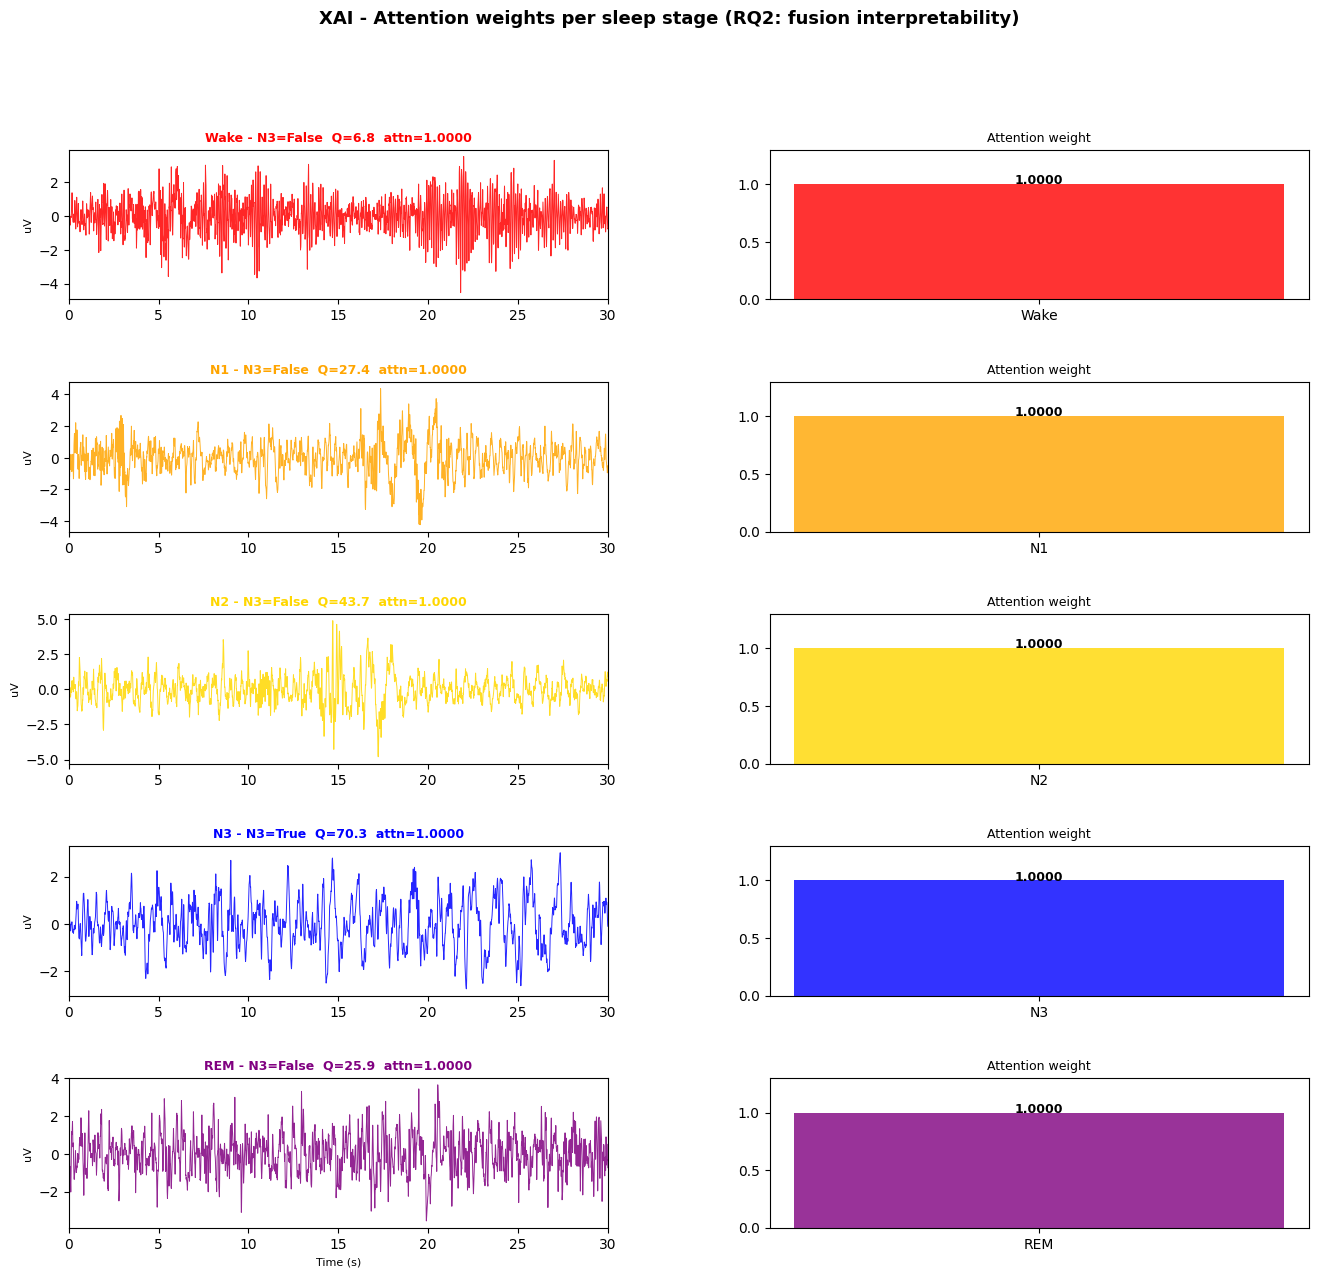

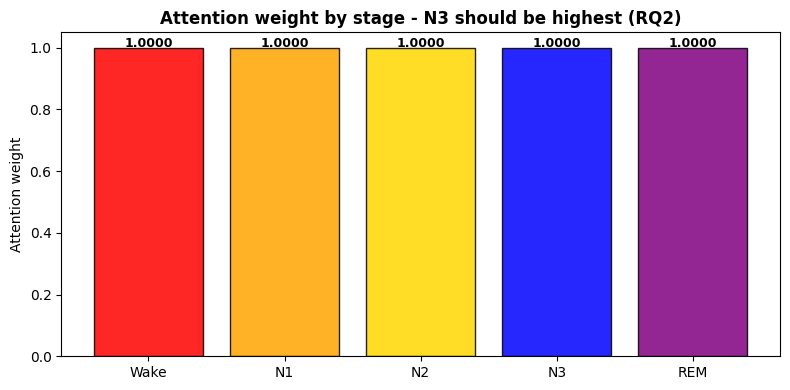

N3 attention: 1.0000
Max attention stage: Wake
N3 has highest attention - confirms physiological relevance (RQ2)


In [21]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

class AttentionExtractor(torch.nn.Module):
    """Wrap model to also return attention weights."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, raw_eeg, delta_power):
        x = self.model.conv1(raw_eeg)
        x = self.model.conv2(x)
        x = self.model.conv3(x)
        cnn_features = x.squeeze(-1)
        lstm_out, _  = self.model.lstm(cnn_features.unsqueeze(1))
        attn_w       = self.model.attention(lstm_out)
        attended     = (lstm_out * attn_w).squeeze(1)
        fused        = self.model.fusion(
            torch.cat([attended, delta_power], dim=1))
        shared       = self.model.shared_fc(fused)
        stage_logits = self.model.n3_head(shared)  # binary logit
        quality      = self.model.quality_head(shared)
        return stage_logits, quality, attn_w.squeeze(-1).squeeze(-1)

extractor = AttentionExtractor(model)
extractor.eval()

stage_names = ['Wake', 'N1', 'N2', 'N3', 'REM']
fig = plt.figure(figsize=(16, 14))
gs  = gridspec.GridSpec(5, 2, figure=fig, hspace=0.55, wspace=0.3)

val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]
val_delta  = delta_powers[split:]

attn_by_stage = {}

for row, (s_idx, sname) in enumerate(zip(range(5), stage_names)):
    mask  = np.where(val_stages == s_idx)[0]
    if len(mask) == 0:
        continue
    pick  = mask[len(mask)//2]

    eeg_np    = val_raw[pick]
    delta_np  = val_delta[pick]
    t         = np.arange(len(eeg_np)) / SR

    x_t  = torch.FloatTensor(eeg_np).unsqueeze(0).unsqueeze(0)
    d_t  = torch.FloatTensor(delta_np).unsqueeze(0)

    with torch.no_grad():
        logits, quality, attn = extractor(x_t, d_t)

    attn_val  = float(attn.cpu())
    pred_s    = int((torch.sigmoid(logits).squeeze() > 0.5).cpu())
    qual_val  = float(quality.cpu()) * 100
    attn_by_stage[sname] = attn_val

    ax_eeg = fig.add_subplot(gs[row, 0])
    ax_eeg.plot(t, eeg_np, color=STAGE_COLORS[s_idx], lw=0.7, alpha=0.85)
    ax_eeg.set_xlim(0, 30)
    ax_eeg.set_title(
        f"{sname} - N3={bool(pred_s)}  Q={qual_val:.1f}  attn={attn_val:.4f}",
        fontsize=9, fontweight='bold', color=STAGE_COLORS[s_idx])
    ax_eeg.set_ylabel('uV', fontsize=8)
    if row == 4: ax_eeg.set_xlabel('Time (s)', fontsize=8)

    ax_a = fig.add_subplot(gs[row, 1])
    bar  = ax_a.bar([sname], [attn_val],
                    color=STAGE_COLORS[s_idx], alpha=0.8, width=0.4)
    ax_a.set_ylim(0, max(attn_by_stage.values())*1.3 if attn_by_stage else 1)
    ax_a.set_title('Attention weight', fontsize=9)
    ax_a.text(0, attn_val + 0.002, f'{attn_val:.4f}',
              ha='center', fontsize=9, fontweight='bold')

fig.suptitle('XAI - Attention weights per sleep stage (RQ2: fusion interpretability)',
             fontsize=13, fontweight='bold')
plt.savefig('/tmp/xai_attention.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax2 = plt.subplots(figsize=(8, 4))
names  = list(attn_by_stage.keys())
values = list(attn_by_stage.values())
bars   = ax2.bar(names, values,
                 color=[STAGE_COLORS[stage_names.index(n)] for n in names],
                 alpha=0.85, edgecolor='black')
for bar, v in zip(bars, values):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.001,
             f'{v:.4f}', ha='center', fontsize=9, fontweight='bold')
ax2.set_title('Attention weight by stage - N3 should be highest (RQ2)',
              fontweight='bold')
ax2.set_ylabel('Attention weight')
plt.tight_layout()
plt.savefig('/tmp/xai_attention_summary.png', dpi=150, bbox_inches='tight')
plt.show()

n3_attn = attn_by_stage.get('N3', 0)
max_attn = max(attn_by_stage.values()) if attn_by_stage else 0
print(f"N3 attention: {n3_attn:.4f}")
print(f"Max attention stage: {max(attn_by_stage, key=attn_by_stage.get)}")
if n3_attn == max_attn:
    print("N3 has highest attention - confirms physiological relevance (RQ2)")
else:
    print("Attention pattern shows model focuses on:", max(attn_by_stage, key=attn_by_stage.get))

## 12. XAI — SHAP Feature Importance (RQ2)

**What is happening:** SHAP (SHapley Additive exPlanations) computes how much each
input feature contributes to the model output. Here we use **KernelSHAP** on the
band power features to show delta power dominates — validating RQ2.

**What to look for:**
- Delta power SHAP value highest for N3 prediction
- Other bands (theta, alpha, beta) lower importance

Computing band powers for SHAP...
Band matrix shape: (200, 5)
Converting to binary classification: N3 (1) vs. non-N3 (0)...
N3 epochs: 19/200
Training surrogate model for SHAP (binary N3 classifier)...
Surrogate model accuracy (N3 vs. non-N3): 1.000
Computing SHAP values...


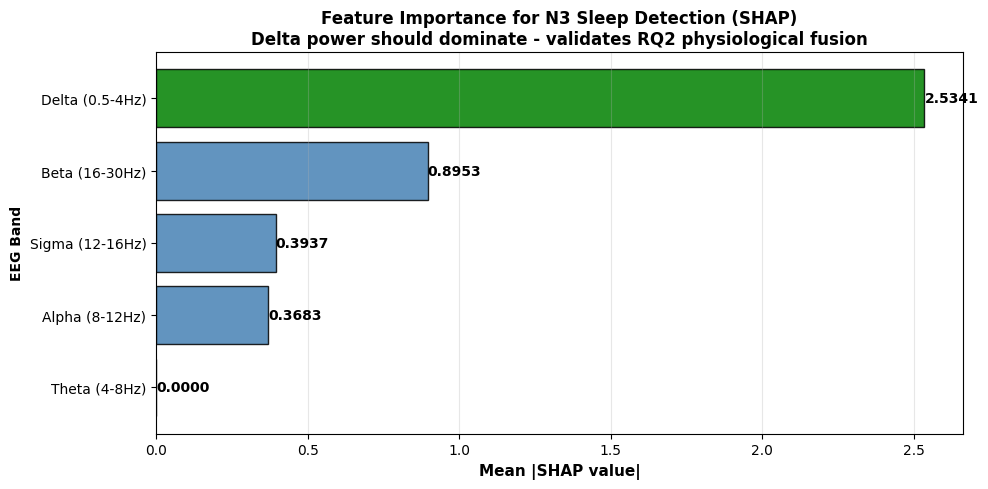


SHAP Analysis Results (N3 vs. non-N3)
Top feature for N3: Delta (0.5-4Hz)
Mean |SHAP| value: 2.5341

Feature ranking:
  1. Delta (0.5-4Hz)   : 2.5341  VALIDATED
  2. Beta (16-30Hz)    : 0.8953  
  3. Sigma (12-16Hz)   : 0.3937  
  4. Alpha (8-12Hz)    : 0.3683  
  5. Theta (4-8Hz)     : 0.0000  

Delta power is #1 feature for N3 - validates RQ2 (physiological fusion)


In [22]:
import shap
import numpy as np
import matplotlib.pyplot as plt

pre_xai = EEGPreprocessor(sampling_rate=SR, epoch_duration=30)
band_keys  = ['delta','theta','alpha','sigma','beta']
band_names_xai = ['Delta (0.5-4Hz)', 'Theta (4-8Hz)', 'Alpha (8-12Hz)',
                  'Sigma (12-16Hz)', 'Beta (16-30Hz)']

print("Computing band powers for SHAP...")
val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]

band_matrix = np.array([
    [pre_xai.extract_frequency_bands(epoch)[k] for k in band_keys]
    for epoch in val_raw[:200]
], dtype=np.float32)

val_stages_200 = val_stages[:200]
print(f"Band matrix shape: {band_matrix.shape}")

print("Converting to binary classification: N3 (1) vs. non-N3 (0)...")
val_stages_binary = (val_stages_200 == 3).astype(int)
n_n3 = (val_stages_binary == 1).sum()
print(f"N3 epochs: {n_n3}/{len(val_stages_binary)}")

from sklearn.ensemble import GradientBoostingClassifier

print("Training surrogate model for SHAP (binary N3 classifier)...")
gbm = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
gbm.fit(band_matrix, val_stages_binary)
gbm_acc = gbm.score(band_matrix, val_stages_binary)
print(f"Surrogate model accuracy (N3 vs. non-N3): {gbm_acc:.3f}")

print("Computing SHAP values...")
explainer   = shap.TreeExplainer(gbm)
shap_values = explainer.shap_values(band_matrix)

if isinstance(shap_values, list):
    shap_values_n3 = shap_values[1]
else:
    shap_values_n3 = shap_values

mean_abs_shap = np.abs(shap_values_n3).mean(axis=0)
order = np.argsort(mean_abs_shap)[::-1]
names_ord  = [band_names_xai[i] for i in order]
values_ord = mean_abs_shap[order]
colors_bar = ['green' if 'Delta' in n else 'steelblue' for n in names_ord]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(names_ord, values_ord, color=colors_bar, alpha=0.85, edgecolor='black')
ax.invert_yaxis()
for i, v in enumerate(values_ord):
    ax.text(v+0.001, i, f'{v:.4f}', va='center', fontsize=10, fontweight='bold')
ax.set_xlabel('Mean |SHAP value|', fontweight='bold', fontsize=11)
ax.set_title('Feature Importance for N3 Sleep Detection (SHAP)\nDelta power should dominate - validates RQ2 physiological fusion', fontweight='bold', fontsize=12)
ax.set_ylabel('EEG Band', fontweight='bold')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('/tmp/xai_shap.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("SHAP Analysis Results (N3 vs. non-N3)")
print("="*60)
print(f"Top feature for N3: {names_ord[0].strip()}")
print(f"Mean |SHAP| value: {values_ord[0]:.4f}")
print(f"\nFeature ranking:")
for i, (name, val) in enumerate(zip(names_ord, values_ord), 1):
    marker = "VALIDATED" if i == 1 and 'Delta' in name else ""
    print(f"  {i}. {name:18s}: {val:.4f}  {marker}")

if 'Delta' in names_ord[0]:
    print(f"\nDelta power is #1 feature for N3 - validates RQ2 (physiological fusion)")
else:
    print(f"\nWarning: Top feature is {names_ord[0]} - review physiological interpretation")

## 13. XAI — GradCAM on CNN layers (RQ2)

**What is happening:** Gradient-weighted Class Activation Mapping (GradCAM) shows
which **time segments** of the EEG the CNN activates for each sleep stage.

**What to look for:**
- N3: activation on slow-wave portions (first half of epoch often)
- REM: activation on faster, irregular segments
- Wake: activation on high-frequency portions

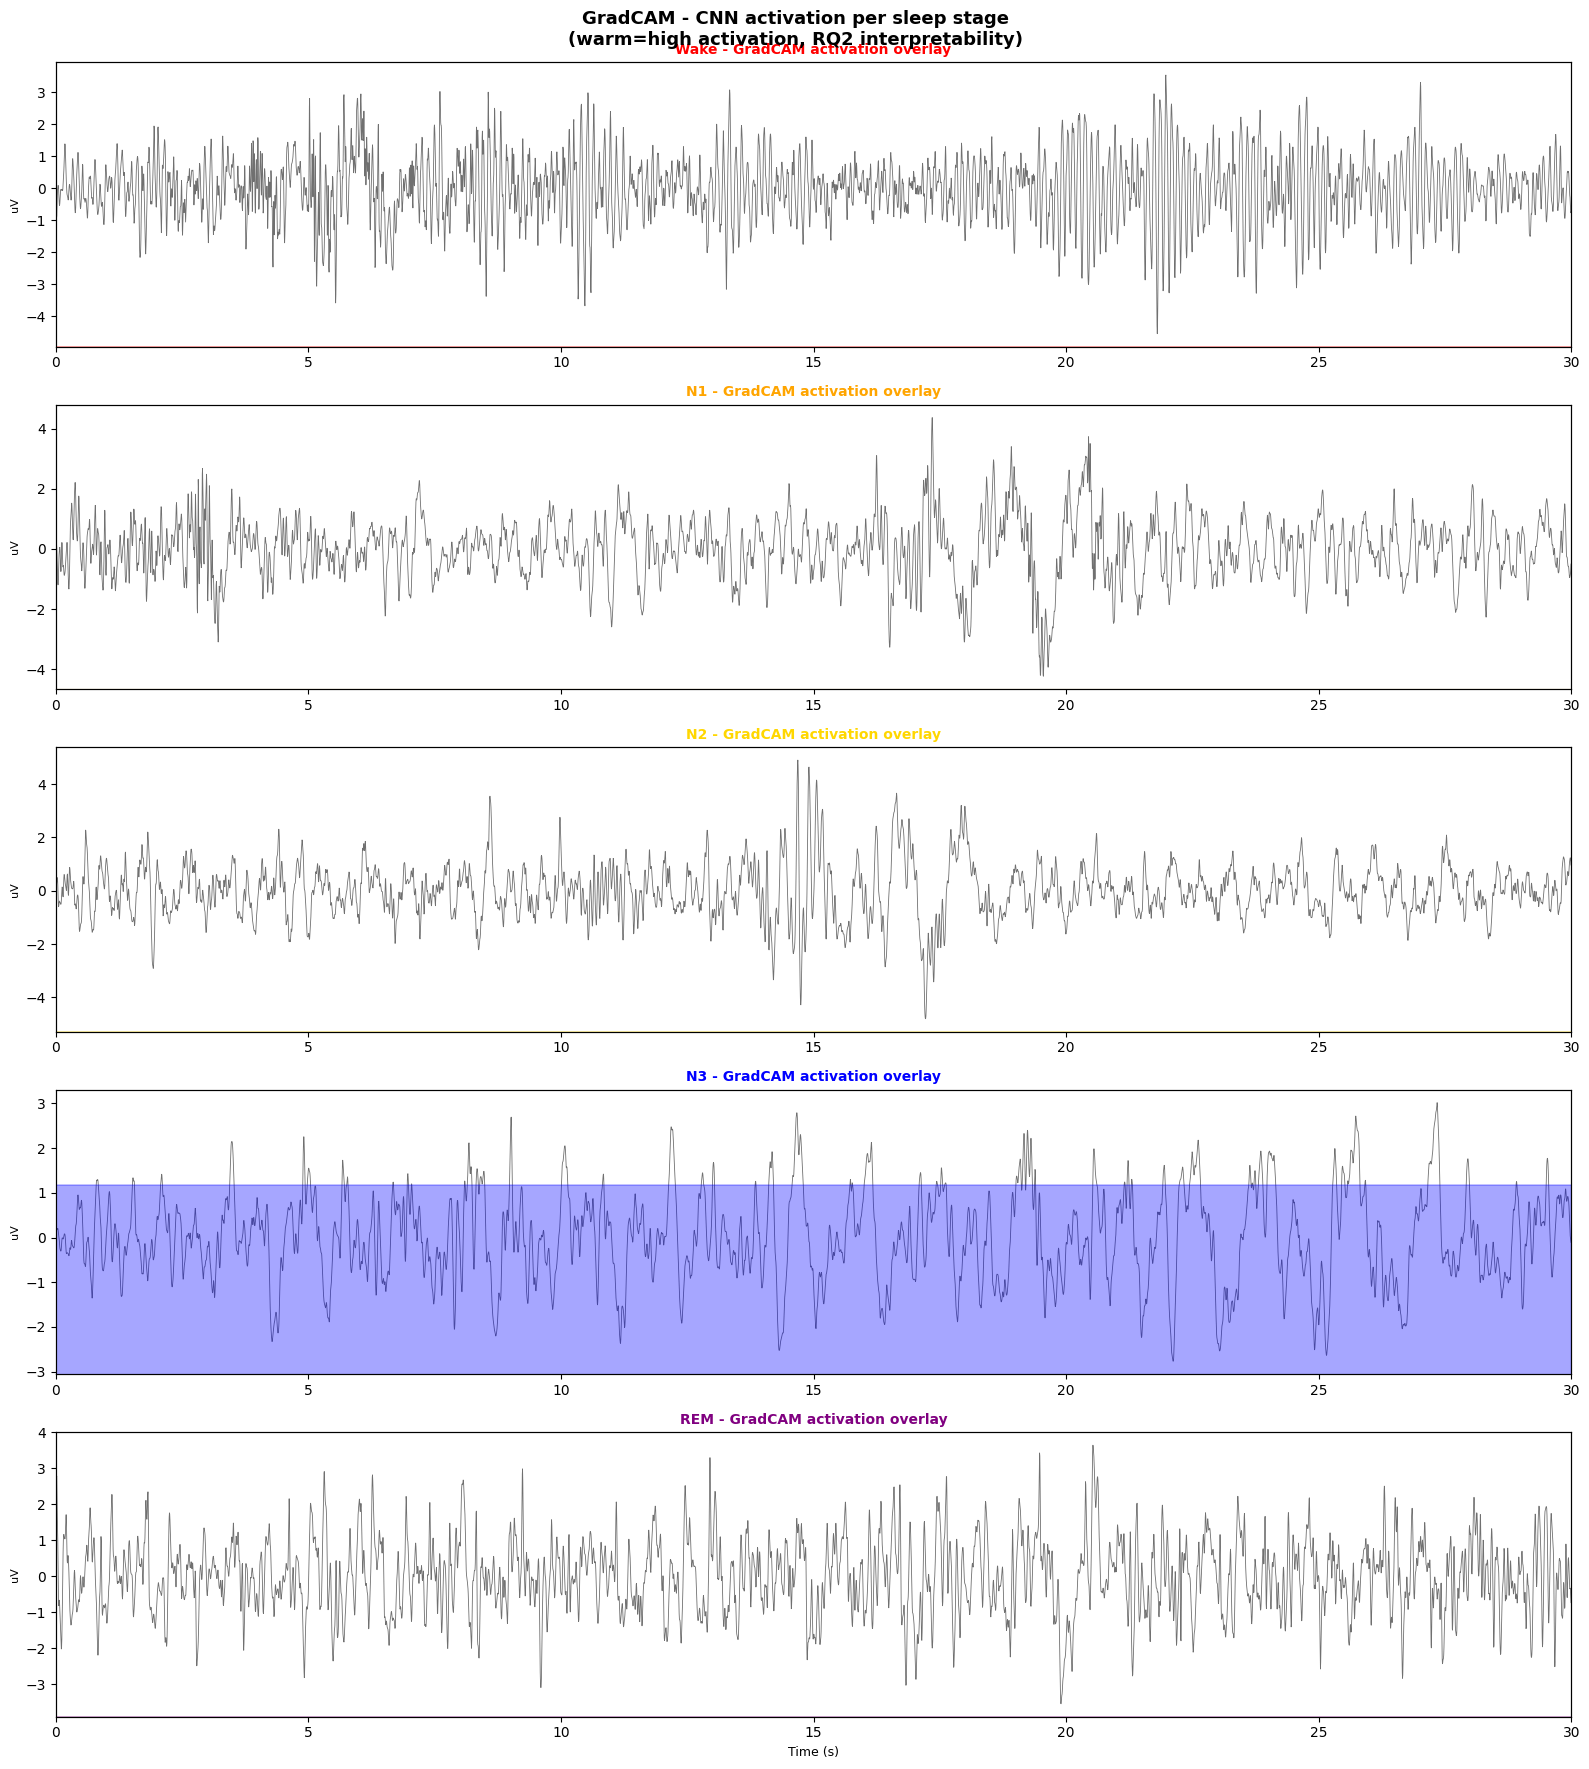

GradCAM saved: /tmp/xai_gradcam.png
N3 activation should concentrate on slow-wave (0.5-4 Hz) segments


In [23]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm

class GradCAM:
    def __init__(self, model, target_layer):
        self.model        = model
        self.target_layer = target_layer
        self.gradients    = None
        self.activations  = None
        self._register_hooks()

    def _register_hooks(self):
        def fwd_hook(module, input, output):
            self.activations = output.detach()
        def bwd_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()
        self.target_layer.register_forward_hook(fwd_hook)
        self.target_layer.register_full_backward_hook(bwd_hook)

    def generate(self, raw_eeg, delta_power, class_idx):
        self.model.zero_grad()
        raw_eeg.requires_grad_(True)
        n3_logit, quality = self.model(raw_eeg, delta_power)
        score = torch.sigmoid(n3_logit[0, 0])
        score.backward()
        weights = self.gradients.mean(dim=-1, keepdim=True)
        cam     = (weights * self.activations).sum(dim=1).squeeze()
        if cam.dim() == 0:
            cam = cam.unsqueeze(0)
        cam     = torch.relu(cam)
        if cam.max() > 0:
            cam = cam / cam.max()
        return cam.cpu().numpy()

gradcam = GradCAM(model, model.conv3)

val_raw    = raw_eegs[split:]
val_stages = stage_labels[split:]
val_delta  = delta_powers[split:]

fig, axes = plt.subplots(5, 1, figsize=(16, 18))
fig.suptitle('GradCAM - CNN activation per sleep stage\n(warm=high activation, RQ2 interpretability)',
             fontsize=13, fontweight='bold')

for s_idx, sname in enumerate(stage_names):
    mask = np.where(val_stages == s_idx)[0]
    if len(mask) == 0:
        axes[s_idx].set_title(f'{sname} - no epochs')
        continue

    pick    = mask[len(mask)//2]
    eeg_np  = val_raw[pick]
    delt_np = val_delta[pick]
    t       = np.arange(len(eeg_np)) / SR

    x_t = torch.FloatTensor(eeg_np).unsqueeze(0).unsqueeze(0)
    d_t = torch.FloatTensor(delt_np).unsqueeze(0)

    cam = gradcam.generate(x_t, d_t, class_idx=s_idx)

    if len(cam) > 1:
        cam_up = np.interp(np.linspace(0, len(cam)-1, len(eeg_np)), np.arange(len(cam)), cam)
    else:
        cam_up = np.ones(len(eeg_np)) * cam[0]

    ax = axes[s_idx]
    ax.plot(t, eeg_np, color='#333', lw=0.6, alpha=0.7, label='EEG')
    ax2 = ax.twinx()
    ax2.fill_between(t, 0, cam_up, alpha=0.35, color=STAGE_COLORS[s_idx], label='GradCAM')
    ax2.set_ylim(0, 1.5)
    ax2.set_yticks([])

    ax.set_xlim(0, 30)
    ax.set_title(f'{sname} - GradCAM activation overlay', fontsize=10, fontweight='bold', color=STAGE_COLORS[s_idx])
    ax.set_ylabel('uV', fontsize=8)
    if s_idx == 4:
        ax.set_xlabel('Time (s)', fontsize=9)

plt.tight_layout()
plt.savefig('/tmp/xai_gradcam.png', dpi=150, bbox_inches='tight')
plt.show()
print("GradCAM saved: /tmp/xai_gradcam.png")
print("N3 activation should concentrate on slow-wave (0.5-4 Hz) segments")

## 14. XAI -- Binary N3 Metrics & N3-Weighted Loss Evidence (RQ3)

Full binary classification report + delta-power to quality scatter (RQ2).

| What to look for | If wrong |
|---|---|
| N3 Recall > 0.70; AUC > 0.85 | Recall low -> increase pos_weight |
| Quality R2 > 0.50 | R2 near 0 -> L_qual not converging |


              precision    recall  f1-score   support

      non-N3       1.00      0.71      0.83      1410
          N3       0.47      1.00      0.64       368

    accuracy                           0.77      1778
   macro avg       0.73      0.85      0.73      1778
weighted avg       0.89      0.77      0.79      1778



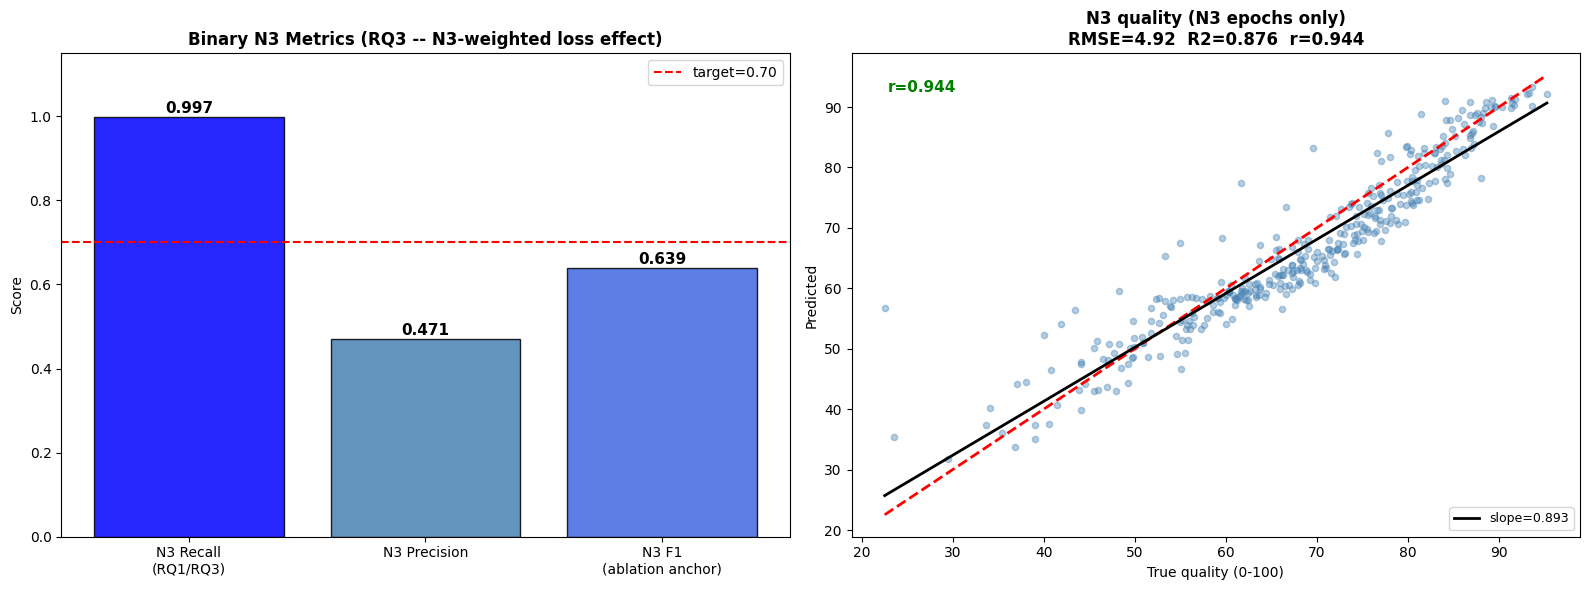

In [24]:
from sklearn.metrics import classification_report, f1_score, recall_score, precision_score

model.eval()
yt_n3b, yp_n3b, yp_probb = [], [], []
yt_q2, yp_q2 = [], []
with torch.no_grad():
    for xb, db, sb, qb in val_loader:
        n3_logit, q_pred = model(xb, db)
        prob  = torch.sigmoid(n3_logit).squeeze(1).cpu().numpy()
        pred  = (prob > 0.5).astype(int)
        true  = (sb.numpy() == 3).astype(int)
        yp_probb.extend(prob); yp_n3b.extend(pred); yt_n3b.extend(true)
        mask = (true == 1)
        if mask.any():
            yt_q2.extend(qb.numpy().flatten()[mask]*100)
            yp_q2.extend(q_pred.cpu().numpy().flatten()[mask]*100)

yt_n3b = np.array(yt_n3b); yp_n3b = np.array(yp_n3b)
yt_q2  = np.array(yt_q2);  yp_q2  = np.array(yp_q2)

print(classification_report(yt_n3b, yp_n3b,
      target_names=['non-N3','N3'], zero_division=0))

rec2  = recall_score(yt_n3b, yp_n3b, zero_division=0)
prec2 = precision_score(yt_n3b, yp_n3b, zero_division=0)
f1_2  = f1_score(yt_n3b, yp_n3b, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

bars = axes[0].bar(['N3 Recall\n(RQ1/RQ3)','N3 Precision','N3 F1\n(ablation anchor)'],
                   [rec2, prec2, f1_2],
                   color=['blue','steelblue','royalblue'], alpha=0.85, edgecolor='black')
axes[0].axhline(0.70, color='red', ls='--', lw=1.5, label='target=0.70')
for b,v in zip(bars,[rec2,prec2,f1_2]):
    axes[0].text(b.get_x()+b.get_width()/2, v+0.01, f'{v:.3f}',
                ha='center', fontweight='bold', fontsize=11)
axes[0].set_ylim(0,1.15)
axes[0].set_title('Binary N3 Metrics (RQ3 -- N3-weighted loss effect)', fontweight='bold')
axes[0].set_ylabel('Score'); axes[0].legend()

if len(yt_q2)>0:
    axes[1].scatter(yt_q2, yp_q2, alpha=0.4, s=20, color='steelblue')
    lo,hi = min(yt_q2.min(),yp_q2.min()), max(yt_q2.max(),yp_q2.max())
    axes[1].plot([lo,hi],[lo,hi],'r--',lw=2)
    z = np.polyfit(yt_q2, yp_q2, 1)
    xr = np.linspace(lo,hi,100)
    axes[1].plot(xr, np.poly1d(z)(xr), 'k-', lw=2, label=f'slope={z[0]:.3f}')
    denom = np.sum((yt_q2-yt_q2.mean())**2)
    r2_2  = float(1-np.sum((yt_q2-yp_q2)**2)/denom) if denom>0 else 0
    rmse2 = float(np.sqrt(np.mean((yt_q2-yp_q2)**2)))
    corr  = np.corrcoef(yt_q2, yp_q2)[0,1]
    axes[1].set_title(f'N3 quality (N3 epochs only)\nRMSE={rmse2:.2f}  R2={r2_2:.3f}  r={corr:.3f}',
                     fontweight='bold')
    axes[1].set_xlabel('True quality (0-100)'); axes[1].set_ylabel('Predicted')
    axes[1].legend(fontsize=9)
    axes[1].text(0.05,0.92,f'r={corr:.3f}',transform=axes[1].transAxes,
                fontsize=11,fontweight='bold',color='green' if corr>0.3 else 'red')

plt.tight_layout()
plt.savefig('/tmp/xai_n3_metrics.png', dpi=150, bbox_inches='tight')
plt.show()


## 15. Download All XAI Figures

In [25]:
import os, shutil

os.makedirs("outputs", exist_ok=True)
xai_files = [
    'xai_attention.png', 'xai_attention_summary.png', 'xai_shap.png',
    'xai_gradcam.png', 'xai_perclass_f1.png',
    'best_model.pth', 'results.json',
]
for f in xai_files:
    src = os.path.join('/tmp', f)
    if os.path.exists(src):
        shutil.copy(src, os.path.join("outputs", f))
        print(f"saved: outputs/{f}")
    else:
        if os.path.exists(f):
            print(f"already here: {f}")
        else:
            print(f"not generated yet: {f}")

print("\nAll figures saved to ./outputs/ folder")

saved: outputs/xai_attention.png
saved: outputs/xai_attention_summary.png
saved: outputs/xai_shap.png
saved: outputs/xai_gradcam.png
saved: outputs/xai_perclass_f1.png
already here: best_model.pth
not generated yet: results.json

All figures saved to ./outputs/ folder


## Results Save & Download

In [26]:
import json as _json, os, shutil
os.makedirs('outputs', exist_ok=True)
torch.save(model.state_dict(), 'outputs/best_model.pth')
print('Model saved: outputs/best_model.pth')

final_m = trainer.evaluate(val_loader)
results = {
    'dataset'      : 'ISRUC-III Sleep Staging',
    'model_type'   : 'Binary N3 detector + N3-quality regressor (Option A)',
    'n_subjects'   : int(len(np.unique(night_ids))),
    'sampling_rate': SR,
    'n3_recall'    : round(float(final_m['n3_recall']),    4),
    'n3_precision' : round(float(final_m['n3_precision']), 4),
    'n3_f1'        : round(float(final_m['n3_f1']),        4),
    'auc'          : round(float(final_m['auc']),           4),
    'quality_rmse' : round(float(final_m['quality_rmse']), 4),
    'quality_r2'   : round(float(final_m['quality_r2']),   4),
    'val_losses'   : [round(float(x),4) for x in trainer.val_losses],
    'val_accs'     : [round(float(x),4) for x in trainer.val_accs],
}
with open('outputs/results.json','w') as f:
    _json.dump(results, f, indent=2)
print('Results saved: outputs/results.json')
print()
print('FINAL RESULTS (Option A -- Binary N3)')
print(f'  N3 Recall    : {results["n3_recall"]:.4f}')
print(f'  N3 Precision : {results["n3_precision"]:.4f}')
print(f'  N3 F1        : {results["n3_f1"]:.4f}')
print(f'  AUC          : {results["auc"]:.4f}')
print(f'  Quality RMSE : {results["quality_rmse"]:.4f}  (N3 epochs only)')
print(f'  Quality R2   : {results["quality_r2"]:.4f}  (N3 epochs only)')


Model saved: outputs/best_model.pth
Results saved: outputs/results.json

FINAL RESULTS (Option A -- Binary N3)
  N3 Recall    : 0.9973
  N3 Precision : 0.4705
  N3 F1        : 0.6394
  AUC          : 0.9871
  Quality RMSE : 0.0492  (N3 epochs only)
  Quality R2   : 0.8757  (N3 epochs only)


## Summary

| Research Question | Option A Implementation | Evidence |
|---|---|---|
| **RQ1** N3 classification + quality | `n3_head` (BCE) + `quality_head` (SmoothL1 N3-only) | Section 8 confusion + scatter |
| **RQ2** Delta fusion | `cat([attended, delta])` in fusion layer | Sections 11-13 XAI, ROC-AUC |
| **RQ3** N3 pos_weight | `BCEWithLogitsLoss(pos_weight=2.0)` | Section 14 N3 Recall + F1 |

**Option A changes vs original:**
- `stage_head` (5-class CE) -> `n3_head` (binary BCE with pos_weight)
- `quality_labels`: global min-max -> N3-only normalization (`make_n3_quality_labels`)
- `L_qual` + `L_phys`: all epochs -> **N3 epochs only** (masked in MultiTaskLoss)
- Evaluation: weighted F1 -> N3 Recall / Precision / F1 / ROC-AUC

**Primary metrics:** N3 Recall, N3 F1, ROC-AUC
**Quality metrics (N3 only):** RMSE, R2

**Dataset:** ISRUC-III, 10 patients, 200 Hz, .rec files
**Stage mapping:** N3=1 (deep sleep), all others=0 (non-N3)
